# Caso 2 · Nodo Internet: predicción de bajas de clientes

**Equipo:** _completar nombres_

Este notebook sigue las consignas del enunciado (pasos 1 a 24). Cada paso tiene su celda; agreguen todas las que necesiten.
Las funciones de `src/` se completan en los archivos `.py`, no en el notebook. Antes de entregar: *Reiniciar y ejecutar todo*.

In [1]:
%load_ext autoreload
%autoreload 2
# autoreload vuelve a cargar los módulos de src/ cada vez que los modifican, sin reiniciar el notebook.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEMILLA = 42

from src.preparacion import agregar_variables, normalizar_metodo_pago
from src.knn import EscaladorEstandar, KNNClasificador
from src.negocio import SUPUESTOS, ganancia_campania, lift, mejor_umbral, probabilidad_de_equilibrio, resultado_por_contacto

### Estado de las pruebas automáticas
Ejecuten esta celda cada vez que terminen una función de `src/`.

In [2]:
import sys
!"{sys.executable}" -m pytest -q --tb=no -rf

............................................                             [100%]
44 passed in 2.09s


## Parte A · Exploración y preparación (`src/preparacion.py`)

**Paso 1.** Carguen `datos/clientes_historico.csv` e informen filas, tipos, nulos por columna, cuentas de empleados, tasa de baja y valores distintos de `metodo_pago`.

In [3]:
# Tu código aquí
df = pd.read_csv('datos/clientes_historico.csv')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_cliente              20000 non-null  str    
 1   fecha_corte             20000 non-null  str    
 2   segmento                20000 non-null  str    
 3   fecha_alta              20000 non-null  str    
 4   edad_titular            20000 non-null  int64  
 5   zona                    20000 non-null  str    
 6   plan_mbps               20000 non-null  int64  
 7   tipo_contrato           20000 non-null  str    
 8   fin_permanencia         8509 non-null   str    
 9   tiene_tv                20000 non-null  str    
 10  metodo_pago             20000 non-null  str    
 11  dia_vencimiento         20000 non-null  int64  
 12  cargo_mensual_gs        20000 non-null  int64  
 13  uso_mensual_gb          19411 non-null  float64
 14  dispositivos_promedio   20000 non-null  int64  
 

In [5]:
df.head()

,id_cliente,fecha_corte,segmento,fecha_alta,edad_titular,zona,plan_mbps,tipo_contrato,fin_permanencia,tiene_tv,...,uso_mensual_gb,dispositivos_promedio,velocidad_medida_pct,horas_sin_servicio_90d,reclamos_tecnicos_90d,visitas_tecnicas_12m,facturas_atrasadas_6m,consulto_baja_web_30d,motivo_baja,baja_90d
0,NI-118189,2026-05-31,residencial,2018-12-16,43,centro,300,12_meses,2026-12-16,no,...,242.1,3,88.0,0.7,0,1,0,0,NaN,0
1,NI-119690,2026-05-31,residencial,2023-12-03,33,este,600,mensual,NaN,no,...,327.1,3,99.2,0.7,0,0,0,0,competencia,1
2,NI-113950,2026-05-31,residencial,2017-10-23,22,sur,100,mensual,NaN,no,...,78.0,5,94.7,0.0,0,1,1,0,NaN,0
3,NI-118995,2026-05-31,residencial,2026-05-06,62,norte,300,12_meses,2027-05-06,no,...,587.1,3,NaN,3.7,1,0,0,0,NaN,0
4,NI-112506,2026-05-31,residencial,2020-05-20,47,oeste,300,12_meses,2027-05-21,no,...,823.2,10,NaN,0.0,0,0,1,0,NaN,0


### Total de empleados

In [6]:
df['segmento'].unique()

<StringArray>
['residencial', 'empleado']
Length: 2, dtype: str

In [7]:
total_empleados = (df['segmento'] == 'empleado').sum()
total_empleados

np.int64(612)

hay un total de 612 empleados

### Tasa de baja

In [8]:
tasa_bajas = df['baja_90d'].mean()
tasa_bajas

np.float64(0.07675)

La tasa de bajas es del 7.68%

### Valores distintos que figuran en metodo_pago

In [9]:
df['metodo_pago'].unique()

<StringArray>
[     'debito_automatico',          'transferencia',          'Transferencia',
               'efectivo',      'Debito_Automatico',        'tarjeta_credito',
 'transferencia bancaria',              'efectivo ',        'TARJETA CREDITO',
        'Tarjeta_Credito',      'DEBITO AUTOMATICO',               'EFECTIVO',
     'Tarjeta de crédito',          'TRANSFERENCIA',      'debito automatico',
               'Efectivo',        'tarjeta credito',      'Débito automático']
Length: 18, dtype: str

**Paso 2.** Implementen `normalizar_metodo_pago` y `agregar_variables` hasta que pasen `tests/test_preparacion.py`. Apliquen la función y excluyan las cuentas de empleados.

In [10]:
# Tu código aquí
df_clean = agregar_variables(df)
# La población objetivo excluye las cuentas de empleados.
df_clean = df_clean.loc[df_clean['segmento'].eq('residencial')].copy()


**Paso 3.** Tasa de baja por tipo de contrato, `sin_permanencia_3m`, zona, antigüedad, reclamos técnicos y consulta de baja web; zona este con cargo mayor a Gs. 280.000 contra el resto. Tres hallazgos para el negocio.

In [11]:

tasa_contrato = (
    df_clean.groupby('tipo_contrato')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

tasa_permanencia = (
    df_clean.groupby('sin_permanencia_3m')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

tasa_zona = (
    df_clean.groupby('zona')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

tasa_reclamos = (
    df_clean.groupby('reclamos_tecnicos_90d')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

tasa_web = (
    df_clean.groupby('consulto_baja_web_30d')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

In [12]:
df_clean['antiguedad_meses'].unique()

array([ 89.45466491,  29.89487516, 103.21944809, ..., 103.61366623,
        70.8935611 ,  90.24310118], shape=(3267,))

In [13]:
def agregar_variables_derivadas(clientes):
    """Copia de `clientes` con dos variables derivadas que también usa el modelo:
    - tramo_antiguedad: antigüedad agrupada en cinco tramos.
    - grupo_segmento: zona este con cargo mayor a Gs. 280.000 contra el resto.
    Solo usan datos conocidos a la fecha de corte. En el Paso 21 se aplica igual a la campaña.
    """
    resultado = clientes.copy()
    resultado['tramo_antiguedad'] = pd.cut(
        resultado['antiguedad_meses'],
        bins=[-1, 6, 12, 24, 48, np.inf],
        labels=[
            '0-6 meses',
            '6-12 meses',
            '12-24 meses',
            '24-48 meses',
            'Más de 48m',
        ],
    )
    condicion_este_alto = (resultado['zona'].str.lower() == 'este') & (
        resultado['cargo_mensual_gs'] > 280000
    )
    resultado['grupo_segmento'] = np.where(
        condicion_este_alto, 'Zona Este (>280k Gs)', 'Resto de Clientes'
    )
    return resultado


df_clean = agregar_variables_derivadas(df_clean)

tasa_antiguedad = (
    df_clean.groupby('tramo_antiguedad', observed=False)['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

tasa_segmento_especifico = (
    df_clean.groupby('grupo_segmento')['baja_90d']
    .agg(total_clientes='count', tasa_baja_pct=lambda x: x.mean() * 100)
    .round(2)
)

In [14]:
df_clean.info()

<class 'pandas.DataFrame'>
Index: 19388 entries, 0 to 19999
Data columns (total 28 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   id_cliente                   19388 non-null  str           
 1   fecha_corte                  19388 non-null  datetime64[us]
 2   segmento                     19388 non-null  str           
 3   fecha_alta                   19388 non-null  datetime64[us]
 4   edad_titular                 19388 non-null  int64         
 5   zona                         19388 non-null  str           
 6   plan_mbps                    19388 non-null  int64         
 7   tipo_contrato                19388 non-null  str           
 8   fin_permanencia              8256 non-null   datetime64[us]
 9   tiene_tv                     19388 non-null  str           
 10  metodo_pago                  19388 non-null  str           
 11  dia_vencimiento              19388 non-null  int64       

In [15]:
print('=== TASA DE BAJA POR TIPO DE CONTRATO ===\n', tasa_contrato, '\n')
print(
    '=== TASA DE BAJA POR SIN PERMANENCIA 3M ===\n', tasa_permanencia, '\n'
)
print('=== TASA DE BAJA POR ZONA ===\n', tasa_zona, '\n')
print('=== TASA DE BAJA POR ANTIGÜEDAD ===\n', tasa_antiguedad, '\n')
print('=== TASA DE BAJA POR RECLAMOS TÉCNICOS ===\n', tasa_reclamos, '\n')
print('=== TASA DE BAJA POR CONSULTA WEB BAJA ===\n', tasa_web, '\n')
print('=== SEGMENTO ZONA ESTE (>280K) VS RESTO ===\n', tasa_segmento_especifico)

=== TASA DE BAJA POR TIPO DE CONTRATO ===
                total_clientes  tasa_baja_pct
tipo_contrato                               
12_meses                 5584           5.44
24_meses                 2672           4.15
mensual                 11132          10.04 

=== TASA DE BAJA POR SIN PERMANENCIA 3M ===
                     total_clientes  tasa_baja_pct
sin_permanencia_3m                               
0                             6651           3.80
1                            12737          10.05 

=== TASA DE BAJA POR ZONA ===
         total_clientes  tasa_baja_pct
zona                                 
centro            3537           5.65
este              3915          15.43
norte             4242           5.63
oeste             3456           7.41
sur               4238           5.52 

=== TASA DE BAJA POR ANTIGÜEDAD ===
                   total_clientes  tasa_baja_pct
tramo_antiguedad                               
0-6 meses                   3189           9.00
6-1

### Hallazgos del Paso 3

1. **El contrato mensual y la falta de permanencia concentran las bajas.** Los clientes mensuales se van al 10,0%, el doble que los de 12 meses (5,4%) y 24 meses (4,2%). Quienes pueden irse sin penalidad en los próximos 3 meses tienen 10,1% de bajas, contra 3,8% del resto. Ofrecer pasar a un contrato con permanencia junto con el descuento es una palanca concreta.
2. **La zona este, sobre todo con cargo alto, es el foco geográfico.** La zona este pierde el 15,4% de sus clientes, contra 5,5% a 7,4% en las demás. Dentro de ella, los 1.375 clientes que pagan más de Gs. 280.000 llegan a **28,2%**, contra 6,4% del resto de la base: casi el 29,5% a partir del cual conviene llamar (Paso 15). Sugiere un problema de precio o de competencia en esa zona.
3. **La intención de irse y la mala calidad anticipan la baja.** Haber consultado la baja en la web en los últimos 30 días eleva la tasa a 38,9% (contra 6,0%). La tasa crece con los reclamos técnicos: 5,7% sin reclamos, 13,8% con dos y 25,6% con cuatro. La antigüedad separa menos: los primeros 12 meses rondan 8,6% a 9,0% y el tramo de 12 a 24 meses es el más bajo (5,6%).

**Paso 4.** Columnas que no pueden usarse como variables y por qué. Demuestren con una tabla el problema de la columna que haría parecer excelente a cualquier modelo.

In [16]:

tiene_motivo = df_clean['motivo_baja'].notna().map(
    {True: 'Tiene Motivo (Not NaN)', False: 'Sin Motivo (NaN)'}
)


tabla_leakage = pd.crosstab(
    tiene_motivo,
    df_clean['baja_90d'].map({1: 'Baja (1)', 0: 'Activo (0)'}),
    margins=True,
    margins_name='Total',
)

print(tabla_leakage)

baja_90d                Activo (0)  Baja (1)  Total
motivo_baja                                        
Sin Motivo (NaN)             17855         0  17855
Tiene Motivo (Not NaN)           0      1533   1533
Total                        17855      1533  19388


### Columnas que no se usan como variables

- **`motivo_baja`: la columna trampa.** Solo se completa cuando el cliente ya se fue. La tabla lo demuestra: los 1.533 clientes con motivo son exactamente las 1.533 bajas, y ningún cliente activo tiene motivo. Un modelo que la usara parecería perfecto en el histórico, pero en la campaña no sirve: nadie se fue todavía y la columna ni siquiera existe en `clientes_campania.csv`. Sí se conserva en `df_clean` para explicar a los vecinos (Paso 20).
- **`baja_90d`:** es la variable que queremos predecir.
- **`id_cliente`:** es un identificador; no describe al cliente y solo agregaría ruido a las distancias.
- **`fecha_alta`, `fecha_corte`, `fin_permanencia`:** las fechas crudas no son comparables entre la foto de mayo y la de septiembre. Su información ya está en `antiguedad_meses`, `meses_hasta_fin_permanencia` y `sin_permanencia_3m`, calculadas a la fecha de corte de cada fila.
- **`segmento`:** tras excluir a los empleados vale siempre `residencial` y no aporta información.

Las variables derivadas del Paso 3 (`tramo_antiguedad` y `grupo_segmento`) sí se usan: dependen solo de datos conocidos a la fecha de corte y mejoran el AP de validación. `agregar_variables_derivadas` las calcula igual para la campaña.

**Paso 5.** División 75/25 estratificada por `baja_90d` con `random_state=42`.

In [17]:
from sklearn.model_selection import train_test_split
import pandas as pd

columnas_a_excluir = [
    'baja_90d',
    'motivo_baja',
    'id_cliente',
    'fecha_corte',
    'fecha_alta',
    'fin_permanencia',
    'segmento',  # constante tras excluir empleados: no aporta información
]

X = df_clean.drop(columns=columnas_a_excluir)
y = df_clean['baja_90d']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

## Parte B · Preprocesamiento y KNN desde cero (`src/knn.py`)

**Paso 6.** `ColumnTransformer`: imputación por mediana, `np.log1p` en `uso_mensual_gb` y `horas_sin_servicio_90d`, estandarización y `OneHotEncoder(handle_unknown="ignore")`.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    StandardScaler,
)

cols_log = ['uso_mensual_gb', 'horas_sin_servicio_90d']
cols_categoricas = (
    X_train.select_dtypes(include=['object', 'string', 'category'])
    .columns.tolist()
)


cols_numericas = [
    col
    for col in X_train.columns
    if col not in cols_log and col not in cols_categoricas
]


pipeline_log = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='median')),
        ('log1p', FunctionTransformer(np.log1p, validate=True)),
        ('scaler', StandardScaler()),
    ]
)

pipeline_num = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

pipeline_cat = Pipeline(
    [
        ('imputer', SimpleImputer(strategy='most_frequent')),
        (
            'encoder',
            OneHotEncoder(handle_unknown='ignore', sparse_output=False),
        ),
    ]
)


preprocessor = ColumnTransformer(
    transformers=[
        ('num_log', pipeline_log, cols_log),
        ('num_std', pipeline_num, cols_numericas),
        ('cat_ohe', pipeline_cat, cols_categoricas),
    ],
    remainder='drop',
)


X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

**Paso 7.** Implementen `EscaladorEstandar` y `KNNClasificador` hasta que pasen `tests/test_knn.py`.

In [19]:
# Tu código aquí

**Paso 8.** Su `KNNClasificador` contra `KNeighborsClassifier` con k=51 y pesos por distancia: probabilidades iguales y tiempo de cada uno.

In [20]:
import time


from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    log_loss,
    balanced_accuracy_score,
    confusion_matrix,
    matthews_corrcoef,
)


knn_propio = KNNClasificador(
    k=51,
    pesos="distancia",
    metrica="euclidea",
    tamano_lote=1000
)

knn_sklearn = KNeighborsClassifier(
    n_neighbors=51,
    weights="distance",
    metric="euclidean"
)

modelos = {
    "KNN Propio": knn_propio,
    "KNN Scikit-Learn": knn_sklearn,
}


resultados = []
probabilidades = {}
predicciones = {}

for nombre, modelo in modelos.items():

    t0 = time.perf_counter()
    modelo.fit(X_train_prep, y_train)
    tiempo_fit = time.perf_counter() - t0

    t0 = time.perf_counter()
    probas = modelo.predict_proba(X_test_prep)
    tiempo_predict = time.perf_counter() - t0


    probas_positivas = probas[:, 1]

    y_pred = (probas_positivas >= 0.5).astype(int)

    probabilidades[nombre] = probas
    predicciones[nombre] = y_pred

  
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()


    resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probas_positivas
        ),
        "PR-AUC (AP)": average_precision_score(
            y_test, probas_positivas
        ),
        "Log Loss": log_loss(
            y_test, probas, labels=[0, 1]
        ),
        "MCC": matthews_corrcoef(y_test, y_pred),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Tiempo Fit (s)": tiempo_fit,
        "Tiempo Predict (s)": tiempo_predict,
        "Tiempo Total (s)": tiempo_fit + tiempo_predict,
    })



df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.set_index("Modelo")

print("=== COMPARACIÓN DE MÉTRICAS ===")
display(df_resultados.round(4).T)



probas_propio = probabilidades["KNN Propio"]
probas_sklearn = probabilidades["KNN Scikit-Learn"]

pred_propio = predicciones["KNN Propio"]
pred_sklearn = predicciones["KNN Scikit-Learn"]

son_iguales = np.allclose(
    probas_propio,
    probas_sklearn,
    atol=1e-5
)

diferencia_max = np.max(
    np.abs(probas_propio - probas_sklearn)
)

diferencia_media = np.mean(
    np.abs(probas_propio - probas_sklearn)
)

coincidencia_predicciones = np.mean(
    pred_propio == pred_sklearn
)

print("\n=== EQUIVALENCIA ===")
print(f"Probabilidades equivalentes : {son_iguales}")
print(f"Diferencia máxima absoluta  : {diferencia_max:.8f}")
print(f"Diferencia media absoluta   : {diferencia_media:.8f}")
print(f"Coincidencia predicciones   : {coincidencia_predicciones:.2%}")


t_propio = df_resultados.loc[
    "KNN Propio", "Tiempo Total (s)"
]

t_sklearn = df_resultados.loc[
    "KNN Scikit-Learn", "Tiempo Total (s)"
]

print("\n=== RENDIMIENTO ===")
print(f"Tiempo KNN Propio        : {t_propio:.4f} s")
print(f"Tiempo KNN Scikit-Learn  : {t_sklearn:.4f} s")
print(f"Factor tiempo            : {t_propio / t_sklearn:.2f}x")

=== COMPARACIÓN DE MÉTRICAS ===


Modelo,KNN Propio,KNN Scikit-Learn
Accuracy,0.9266,0.9266
Balanced Accuracy,0.5603,0.5603
Precision,0.6957,0.6957
Recall,0.1253,0.1253
F1,0.2124,0.2124
ROC-AUC,0.7895,0.7895
PR-AUC (AP),0.3897,0.3897
Log Loss,0.3258,0.3258
MCC,0.2747,0.2747
TN,4443.0000,4443.0000



=== EQUIVALENCIA ===
Probabilidades equivalentes : True
Diferencia máxima absoluta  : 0.00000000
Diferencia media absoluta   : 0.00000000
Coincidencia predicciones   : 100.00%

=== RENDIMIENTO ===
Tiempo KNN Propio        : 2.5087 s
Tiempo KNN Scikit-Learn  : 0.4128 s
Factor tiempo            : 6.08x


### Conclusión del Paso 8

Con k=51, pesos por distancia y distancia euclídea, nuestro `KNNClasificador` reproduce exactamente a `KNeighborsClassifier`: la diferencia máxima entre probabilidades es 0 y las predicciones coinciden en el 100% de los clientes de prueba. La implementación propia es unas 6 a 7 veces más lenta (los segundos exactos varían entre ejecuciones), porque calcula por fuerza bruta la distancia a todos los clientes de entrenamiento, mientras que scikit-learn usa rutinas compiladas. Para puntuar los 6.000 clientes de la campaña esa diferencia no es un problema.

Las métricas con corte en 0,5 (recall de 12,5%) muestran que ese corte no sirve en este problema: casi ningún cliente llega a 0,5. El umbral se elige con la economía de la campaña en la Parte E.

## Parte C · Ajuste de KNN

**Paso 9.** AP de KNN con k=25, con y sin estandarizar (validación cruzada estratificada de 5 particiones). Expliquen la diferencia.

In [21]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier


cv_paso9 = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEMILLA
)
particiones_paso9 = list(cv_paso9.split(X_train, y_train))

preprocessor_sin_escalar = clone(preprocessor).set_params(
    num_log__scaler='passthrough',
    num_std__scaler='passthrough',
)

modelos_paso9 = {
    'Con estandarización': Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('knn', KNeighborsClassifier(
            n_neighbors=25, weights='distance', metric='euclidean'
        )),
    ]),
    'Sin estandarización': Pipeline([
        ('preprocessor', preprocessor_sin_escalar),
        ('knn', KNeighborsClassifier(
            n_neighbors=25, weights='distance', metric='euclidean'
        )),
    ]),
}


ap_por_fold_paso9 = pd.DataFrame({
    nombre: cross_val_score(
        modelo, X_train, y_train, cv=particiones_paso9,
        scoring='average_precision', n_jobs=1, error_score='raise',
    )
    for nombre, modelo in modelos_paso9.items()
}, index=pd.Index(range(1, 6), name='Partición'))

resumen_paso9 = pd.DataFrame({
    'AP medio': ap_por_fold_paso9.mean(),
    'Desvío entre particiones': ap_por_fold_paso9.std(ddof=1),
})

display(ap_por_fold_paso9.round(4))
display(resumen_paso9.round(4))
print(f'AP de referencia (tasa de baja en entrenamiento): {y_train.mean():.4f}')
diferencia_ap_paso9 = (
    resumen_paso9.loc['Con estandarización', 'AP medio']
    - resumen_paso9.loc['Sin estandarización', 'AP medio']
)
print(f'Diferencia de AP (con - sin): {diferencia_ap_paso9:+.4f}')

,Con estandarización,Sin estandarización
Partición,,
1,0.3708,0.1390
2,0.3566,0.1479
3,0.3481,0.1572
4,0.3818,0.1438
5,0.3852,0.1865


,AP medio,Desvío entre particiones
Con estandarización,0.3685,0.0160
Sin estandarización,0.1549,0.0189


AP de referencia (tasa de baja en entrenamiento): 0.0791
Diferencia de AP (con - sin): +0.2136


Con k=25 y pesos por distancia, el AP medio es **0,3685 con estandarización** (desvío: 0,0160) y **0,1549 sin estandarización** (desvío: 0,0189). La diferencia es de **0,2136 puntos de AP**. AP evalúa el ordenamiento del riesgo; estos valores no son porcentajes de aciertos.

KNN determina los vecinos a partir de las distancias. Sin estandarizar, una variable como cargo_mensual_gs, expresada en cientos de miles, puede dominar la distancia euclídea frente a reclamos, antigüedad o indicadores binarios. Dos clientes pueden resultar vecinos por tener cargos similares aunque difieran en señales de riesgo. Al estandarizar las variables numéricas, sus diferencias se expresan en unidades de desvío estándar y esas señales pueden influir en la elección de los vecinos. En estos datos, esa elección mejora el ordenamiento del riesgo de baja.

La comparación conserva la imputación, log1p y la codificación one-hot; solo se retiran los dos escaladores en la segunda variante. Se reutilizan exactamente las mismas cinco particiones estratificadas y cada Pipeline aprende el preprocesamiento únicamente con el entrenamiento de su partición, evitando fuga de información. El conjunto de prueba final no se usa para calcular estos AP.

**Paso 10.** `GridSearchCV` con `average_precision`: k, pesos y `p`. Gráfico de AP en función de k y explicación del k elegido.

,k,pesos,p,AP medio,Desvío CV
0,801,Por distancia,1,0.4286,0.0106
1,401,Por distancia,1,0.4283,0.0076
2,301,Por distancia,1,0.4268,0.0085
3,201,Por distancia,1,0.4259,0.0094
4,1601,Por distancia,1,0.4247,0.0123
5,801,Uniformes,1,0.4237,0.0101
6,401,Uniformes,1,0.4236,0.0066
7,151,Por distancia,1,0.4225,0.0115
8,301,Uniformes,1,0.4209,0.0084
9,201,Uniformes,1,0.4196,0.0097


Máximo de la grilla: k=801, Por distancia, p=1, AP 0.4286
Error estándar del máximo: 0.0047 -> AP mínimo aceptado: 0.4239
Parámetros elegidos (menor k dentro de un error estándar): {'knn__n_neighbors': 201, 'knn__p': 1, 'knn__weights': 'distance'}
AP medio del elegido: 0.4259


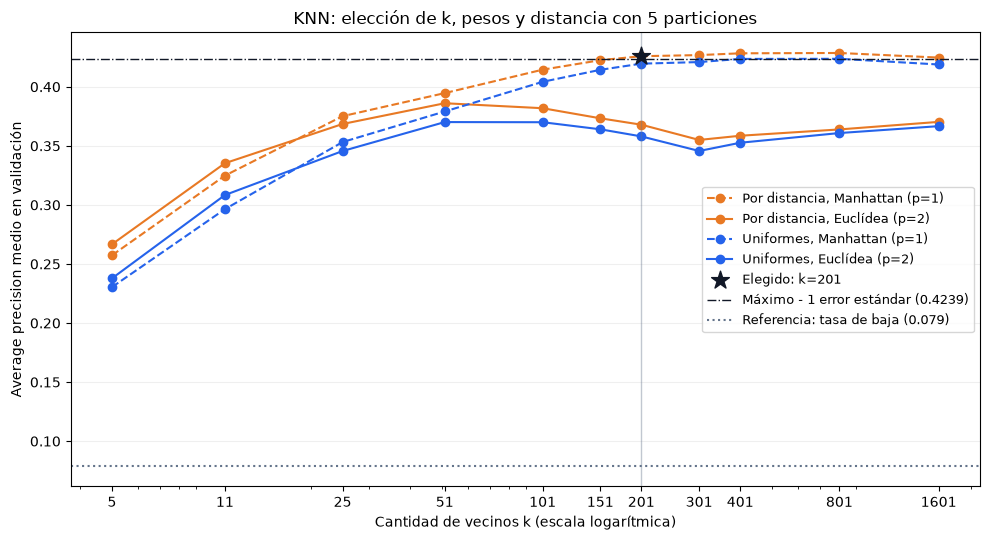

In [22]:
from pathlib import Path

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

# Minkowski: p=1 es Manhattan y p=2 es euclídea.
valores_k = [5, 11, 25, 51, 101, 151, 201, 301, 401, 801, 1601]
grilla_knn = {
    'knn__n_neighbors': valores_k,
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2],
}
pipeline_knn = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('knn', KNeighborsClassifier(metric='minkowski')),
])
cv_paso10 = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=SEMILLA
)


def regla_un_error_estandar(cv_results):
    """Índice de la combinación con el menor k cuyo AP medio queda a menos de un error
    estándar del mejor. Entre combinaciones con ese k, la de mayor AP.

    Las diferencias dentro de un error estándar no se distinguen del ruido entre particiones;
    entre ellas se prefiere el vecindario más chico: más local, mejor calibrado y más fácil
    de explicar al vendedor.
    """
    medias = np.asarray(cv_results['mean_test_score'])
    errores = np.asarray(cv_results['std_test_score']) / np.sqrt(cv_paso10.get_n_splits())
    mejor = np.argmax(medias)
    candidatos = np.flatnonzero(medias >= medias[mejor] - errores[mejor])
    k = np.asarray(cv_results['param_knn__n_neighbors'], dtype=int)
    return candidatos[np.lexsort((-medias[candidatos], k[candidatos]))[0]]


busqueda_knn = GridSearchCV(
    pipeline_knn, grilla_knn, scoring='average_precision',
    cv=cv_paso10, refit=regla_un_error_estandar, n_jobs=1, error_score='raise',
)
busqueda_knn.fit(X_train, y_train)
mejor_knn = busqueda_knn.best_estimator_

resultados_grid_knn = pd.DataFrame(busqueda_knn.cv_results_)
resultados_grid_knn['k'] = resultados_grid_knn[
    'param_knn__n_neighbors'
].astype(int)
resultados_grid_knn['pesos'] = resultados_grid_knn[
    'param_knn__weights'
].map({'uniform': 'Uniformes', 'distance': 'Por distancia'})
resultados_grid_knn['p'] = resultados_grid_knn['param_knn__p'].astype(int)

tabla_grid_knn = resultados_grid_knn[[
    'k', 'pesos', 'p', 'mean_test_score', 'std_test_score',
]].rename(columns={
    'mean_test_score': 'AP medio', 'std_test_score': 'Desvío CV',
}).sort_values('AP medio', ascending=False)
display(tabla_grid_knn.head(10).round(4).reset_index(drop=True))
# Con refit como función, GridSearchCV no define best_score_: se lee de cv_results_.
fila_maximo_knn = resultados_grid_knn.loc[resultados_grid_knn['mean_test_score'].idxmax()]
error_estandar_maximo = fila_maximo_knn['std_test_score'] / np.sqrt(cv_paso10.get_n_splits())
umbral_ap_paso10 = fila_maximo_knn['mean_test_score'] - error_estandar_maximo
mejor_fila_knn = resultados_grid_knn.loc[busqueda_knn.best_index_]
k_elegido = int(mejor_fila_knn['k'])
p_elegido = int(mejor_fila_knn['p'])
pesos_elegidos = mejor_fila_knn['pesos']
ap_elegido = mejor_fila_knn['mean_test_score']

print(f"Máximo de la grilla: k={int(fila_maximo_knn['k'])}, {fila_maximo_knn['pesos']}, "
      f"p={int(fila_maximo_knn['p'])}, AP {fila_maximo_knn['mean_test_score']:.4f}")
print(f'Error estándar del máximo: {error_estandar_maximo:.4f} -> AP mínimo aceptado: {umbral_ap_paso10:.4f}')
print('Parámetros elegidos (menor k dentro de un error estándar):', busqueda_knn.best_params_)
print(f'AP medio del elegido: {ap_elegido:.4f}')

fig_paso10, ax_paso10 = plt.subplots(figsize=(10, 5.5))
colores_paso10 = {'Uniformes': '#2563eb', 'Por distancia': '#e87924'}
for (pesos, p), grupo in resultados_grid_knn.groupby(['pesos', 'p']):
    grupo = grupo.sort_values('k')
    metrica = 'Manhattan' if p == 1 else 'Euclídea'
    ax_paso10.plot(
        grupo['k'], grupo['mean_test_score'], marker='o',
        color=colores_paso10[pesos], linestyle='--' if p == 1 else '-',
        label=f'{pesos}, {metrica} (p={p})',
    )
ax_paso10.scatter(
    k_elegido, ap_elegido, s=180, marker='*',
    color='#111827', zorder=5, label=f'Elegido: k={k_elegido}',
)
ax_paso10.axvline(k_elegido, color='#64748b', alpha=0.4, linewidth=1)
ax_paso10.axhline(
    umbral_ap_paso10, color='#111827', linestyle='-.', linewidth=1,
    label=f'Máximo - 1 error estándar ({umbral_ap_paso10:.4f})',
)
ax_paso10.axhline(
    y_train.mean(), color='#64748b', linestyle=':',
    label=f'Referencia: tasa de baja ({y_train.mean():.3f})',
)
ax_paso10.set_xscale('log')
ax_paso10.set_xticks(valores_k, labels=[str(k) for k in valores_k])
ax_paso10.set_xlabel('Cantidad de vecinos k (escala logarítmica)')
ax_paso10.set_ylabel('Average precision medio en validación')
ax_paso10.set_title('KNN: elección de k, pesos y distancia con 5 particiones')
ax_paso10.grid(axis='y', alpha=0.2)
ax_paso10.legend(fontsize=9, loc='best')
fig_paso10.tight_layout()
Path('figuras').mkdir(exist_ok=True)
fig_paso10.savefig('figuras/paso10_ap_knn.png', dpi=160, bbox_inches='tight')
plt.show()

### Elección del modelo

Se evaluaron 44 combinaciones (once valores de k, dos tipos de pesos y dos valores de p) con cinco particiones estratificadas y average_precision. El máximo de la grilla es k=801 con pesos por distancia y Manhattan (AP 0,4286), pero **se elige k=201, pesos por distancia y p=1 (Manhattan)** con la **regla de un error estándar**: el menor k cuyo AP medio no se distingue del máximo, es decir, que queda a menos de un error estándar (0,0047) de él. k=201 obtiene **0,4259**, por encima del mínimo aceptado (0,4239); k=151 (0,4225) queda justo afuera. La regla se pasa a GridSearchCV como refit, así que el Pipeline se reajusta con todo el entrenamiento y queda disponible como mejor_knn.

**Por qué no menos vecinos.** Solo el 8% de los clientes se va: entre 5 o 25 vecinos suele haber 0, 1 o 2 bajas, y la probabilidad salta entre pocos valores, lo que ordena mal el riesgo. Con k=25 el AP es apenas 0,375.

**Por qué no 801.** Desde k≈200 la curva se aplana: entre k=201 y k=801 el AP sube solo 0,003, menos que el desvío entre particiones (≈0,01). Esa diferencia es ruido y no compensa lo que se pierde. Con 801 vecinos el vecindario abarca el 7% de los clientes de cada partición y deja de ser "los clientes más parecidos"; además, promediar sobre tantos clientes achata todavía más las probabilidades (Paso 14). Con 201 vecinos la estimación es más local y más coherente con la explicación que recibe el vendedor: los 5 vecinos más parecidos del Paso 20 forman parte de los mismos 201 con que se calcula la probabilidad.

Las diez mejores combinaciones usan Manhattan (p=1). Los pesos por distancia hacen que, dentro del vecindario, los clientes más parecidos pesen más. Cada partición aprende imputación, log1p, estandarización y one-hot con su propio entrenamiento, y la selección no usa el conjunto de prueba.

**Paso 11.** AP sin las variables de permanencia y, por separado, sin `edad_titular`, `dispositivos_promedio` ni `dia_vencimiento`. Conclusión.

In [23]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_score

columnas_permanencia = [
    'tipo_contrato', 'meses_hasta_fin_permanencia', 'sin_permanencia_3m',
]
columnas_perfil = [
    'edad_titular', 'dispositivos_promedio', 'dia_vencimiento',
]
grupos_paso11 = {
    'Completo': [],
    'Sin permanencia': columnas_permanencia,
    'Sin edad, dispositivos ni vencimiento': columnas_perfil,
}

def crear_variante_knn(columnas_excluir):

    modelo = clone(mejor_knn)
    prep = modelo.named_steps['preprocessor']
    transformadores = []
    for nombre, transformador, columnas in prep.transformers:
        restantes = [c for c in columnas if c not in columnas_excluir]
        if restantes:
            transformadores.append((nombre, transformador, restantes))
    prep.set_params(transformers=transformadores)
    return modelo


particiones_paso11 = list(cv_paso10.split(X_train, y_train))
modelos_paso11 = {}
puntajes_paso11 = {}
for nombre, columnas_excluir in grupos_paso11.items():
    X_variante = X_train.drop(columns=columnas_excluir)
    modelo = crear_variante_knn(columnas_excluir)
    modelos_paso11[nombre] = modelo
    puntajes_paso11[nombre] = cross_val_score(
        modelo, X_variante, y_train, cv=particiones_paso11,
        scoring='average_precision', n_jobs=1, error_score='raise',
    )

ap_por_fold_paso11 = pd.DataFrame(
    puntajes_paso11, index=pd.Index(range(1, 6), name='Partición'),
)

deltas_por_fold_paso11 = ap_por_fold_paso11.subtract(
    ap_por_fold_paso11['Completo'], axis=0,
)
resumen_paso11 = pd.DataFrame({
    'Variables originales': {
        nombre: X_train.shape[1] - len(columnas)
        for nombre, columnas in grupos_paso11.items()
    },
    'AP medio': ap_por_fold_paso11.mean(),
    'Desvío entre particiones': ap_por_fold_paso11.std(ddof=1),
    'Cambio de AP frente al completo': deltas_por_fold_paso11.mean(),
})

parametros_paso11 = mejor_knn.named_steps['knn'].get_params()
print('Parámetros fijos:', {
    nombre: parametros_paso11[nombre]
    for nombre in ['n_neighbors', 'weights', 'p']
})
display(ap_por_fold_paso11.round(4))
display(resumen_paso11.round(4))
display(deltas_por_fold_paso11.round(4))

Parámetros fijos: {'n_neighbors': 201, 'weights': 'distance', 'p': 1}


,Completo,Sin permanencia,"Sin edad, dispositivos ni vencimiento"
Partición,,,
1,0.4346,0.3659,0.4336
2,0.4120,0.3565,0.4062
3,0.4172,0.3577,0.4030
4,0.4317,0.3582,0.4444
5,0.4340,0.3708,0.4381


,Variables originales,AP medio,Desvío entre particiones,Cambio de AP frente al completo
Completo,21,0.4259,0.0106,0.0000
Sin permanencia,18,0.3618,0.0062,-0.0641
"Sin edad, dispositivos ni vencimiento",18,0.4251,0.0191,-0.0008


,Completo,Sin permanencia,"Sin edad, dispositivos ni vencimiento"
Partición,,,
1,0.0,-0.0687,-0.0010
2,0.0,-0.0555,-0.0057
3,0.0,-0.0594,-0.0142
4,0.0,-0.0735,0.0127
5,0.0,-0.0632,0.0041


### Conclusión del Paso 11

Con k=201, pesos por distancia y p=1, el KNN completo obtiene un AP medio de **0,4259**.

- **Sin las variables de permanencia** (tipo_contrato, meses_hasta_fin_permanencia, sin_permanencia_3m), el AP cae a **0,3618** (**−0,0641**). La caída se repite en las cinco particiones (entre −0,056 y −0,074) y es mucho mayor que la variación entre ellas (≈0,011). Es el grupo de variables más importante, coherente con el Paso 3: quien puede irse sin penalidad se va bastante más.
- **Sin edad_titular, dispositivos_promedio y dia_vencimiento**, el AP es **0,4251** (**−0,0008**), con cambios de signo distinto según la partición. Estas tres variables casi no aportan; se podrían retirar sin pérdida, lo que además simplifica el modelo y la explicación de los vecinos.

Los parámetros se mantienen fijos para aislar el efecto de retirar variables, y cada variante vuelve a aprender el preprocesamiento dentro de cada partición. Estas diferencias muestran qué información usa el modelo, no efectos causales sobre las bajas.

## Parte D · Naive Bayes gaussiano como comparación

**Paso 12.** AP de `GaussianNB` con el mismo preprocesamiento, con y sin transformación logarítmica.

In [24]:

from IPython.display import display
from sklearn.base import clone
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB

particiones_paso12 = list(cv_paso10.split(X_train, y_train))
preprocessor_sin_log = clone(preprocessor).set_params(num_log__log1p='passthrough')
modelos_nb = {
    'GaussianNB con log1p': Pipeline([
        ('preprocessor', clone(preprocessor)), ('nb', GaussianNB()),
    ]),
    'GaussianNB sin log1p': Pipeline([
        ('preprocessor', preprocessor_sin_log), ('nb', GaussianNB()),
    ]),
}

ap_por_fold_paso12 = pd.DataFrame({
    nombre: cross_val_score(
        modelo, X_train, y_train, cv=particiones_paso12,
        scoring='average_precision', n_jobs=1, error_score='raise',
    )
    for nombre, modelo in modelos_nb.items()
}, index=pd.Index(range(1, 6), name='Partición'))
ap_por_fold_paso12.insert(0, 'KNN elegido', ap_por_fold_paso11['Completo'])
resumen_paso12 = pd.DataFrame({
    'AP medio': ap_por_fold_paso12.mean(),
    'Desvío entre particiones': ap_por_fold_paso12.std(ddof=1),
})
display(ap_por_fold_paso12.round(4))
display(resumen_paso12.round(4))
delta_log_paso12 = (ap_por_fold_paso12['GaussianNB con log1p']
                   - ap_por_fold_paso12['GaussianNB sin log1p'])
print(f'Cambio de AP (con - sin log1p): {delta_log_paso12.mean():+.4f}')
print(f'AP de referencia (tasa de baja): {y_train.mean():.4f}')
nombre_mejor_nb = resumen_paso12.loc[list(modelos_nb), 'AP medio'].idxmax()
mejor_nb = clone(modelos_nb[nombre_mejor_nb]).fit(X_train, y_train)
print('Variante elegida:', nombre_mejor_nb)


,KNN elegido,GaussianNB con log1p,GaussianNB sin log1p
Partición,,,
1,0.4346,0.3434,0.3347
2,0.4120,0.3687,0.3486
3,0.4172,0.3436,0.3090
4,0.4317,0.3432,0.3352
5,0.4340,0.3637,0.3525


,AP medio,Desvío entre particiones
KNN elegido,0.4259,0.0106
GaussianNB con log1p,0.3525,0.0126
GaussianNB sin log1p,0.3360,0.0171


Cambio de AP (con - sin log1p): +0.0165
AP de referencia (tasa de baja): 0.0791
Variante elegida: GaussianNB con log1p


### Conclusión del Paso 12
Se conserva la variante con mayor AP medio: **GaussianNB con log1p**. AP mide ordenamiento del riesgo, no porcentaje de aciertos. La tabla usa las mismas cinco particiones que KNN. `log1p` comprime valores altos y puede reducir asimetría; una mejora de AP no demuestra normalidad. GaussianNB estima medias y varianzas por variable y clase. Se conserva el escalado para comparar con el mismo preprocesamiento, aunque GaussianNB no necesita equilibrar distancias. Los indicadores one-hot tampoco son gaussianos: el modelo funciona aquí como una aproximación de referencia.

**Paso 13.** Correlación de Spearman entre las variables de calidad del servicio y relación con el supuesto de independencia.

Todos (entrenamiento)


,velocidad_medida_pct,horas_sin_servicio_90d,reclamos_tecnicos_90d,visitas_tecnicas_12m
velocidad_medida_pct,1.000,-0.235,-0.365,-0.280
horas_sin_servicio_90d,-0.235,1.000,0.289,0.101
reclamos_tecnicos_90d,-0.365,0.289,1.000,0.154
visitas_tecnicas_12m,-0.280,0.101,0.154,1.000


Sin baja (y=0)


,velocidad_medida_pct,horas_sin_servicio_90d,reclamos_tecnicos_90d,visitas_tecnicas_12m
velocidad_medida_pct,1.000,-0.218,-0.343,-0.267
horas_sin_servicio_90d,-0.218,1.000,0.272,0.095
reclamos_tecnicos_90d,-0.343,0.272,1.000,0.141
visitas_tecnicas_12m,-0.267,0.095,0.141,1.000


Con baja (y=1)


,velocidad_medida_pct,horas_sin_servicio_90d,reclamos_tecnicos_90d,visitas_tecnicas_12m
velocidad_medida_pct,1.000,-0.337,-0.455,-0.356
horas_sin_servicio_90d,-0.337,1.000,0.403,0.132
reclamos_tecnicos_90d,-0.455,0.403,1.000,0.232
visitas_tecnicas_12m,-0.356,0.132,0.232,1.000


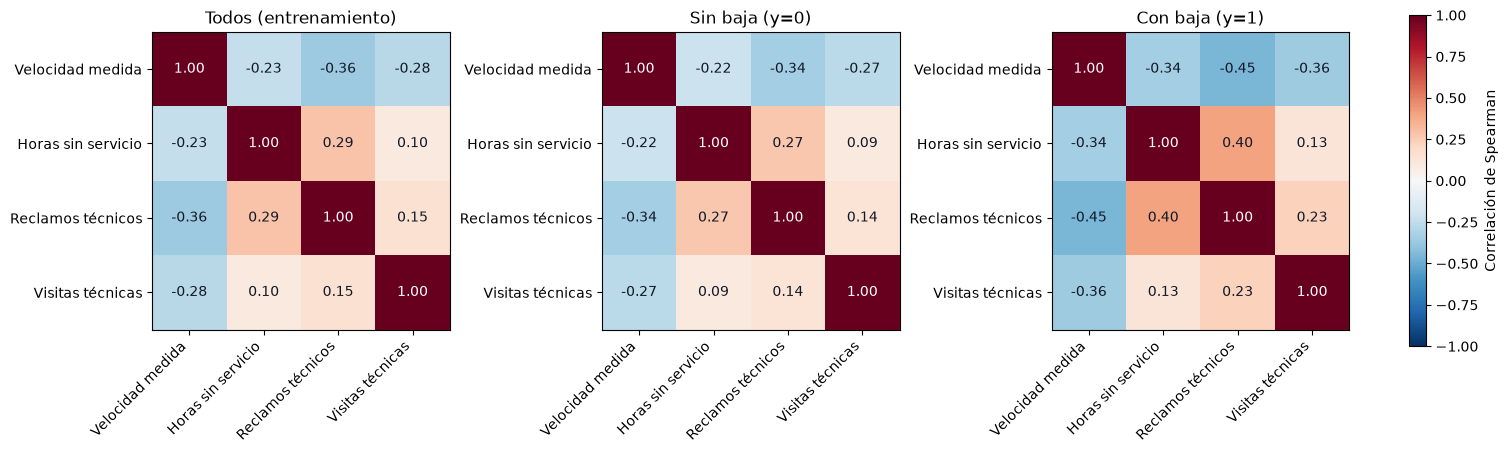

In [25]:

from pathlib import Path

cols_calidad_servicio = [
    'velocidad_medida_pct', 'horas_sin_servicio_90d',
    'reclamos_tecnicos_90d', 'visitas_tecnicas_12m',
]

correlaciones_spearman = {
    'Todos (entrenamiento)': X_train[cols_calidad_servicio].corr(method='spearman'),
    'Sin baja (y=0)': X_train.loc[y_train == 0, cols_calidad_servicio].corr(method='spearman'),
    'Con baja (y=1)': X_train.loc[y_train == 1, cols_calidad_servicio].corr(method='spearman'),
}
etiquetas_calidad = ['Velocidad medida', 'Horas sin servicio', 'Reclamos técnicos', 'Visitas técnicas']
fig_paso13, axes_paso13 = plt.subplots(1, 3, figsize=(15, 5), layout='constrained')
for ax, (nombre, corr) in zip(axes_paso13, correlaciones_spearman.items()):
    print(nombre)
    display(corr.round(3))
    imagen = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
    ax.set_xticks(range(4), etiquetas_calidad, rotation=45, ha='right')
    ax.set_yticks(range(4), etiquetas_calidad)
    ax.set_title(nombre)
    for fila in range(4):
        for columna in range(4):
            valor = corr.iloc[fila, columna]
            ax.text(columna, fila, f'{valor:.2f}', ha='center', va='center',
                    color='white' if abs(valor) > 0.65 else '#111827')
fig_paso13.colorbar(imagen, ax=axes_paso13, shrink=0.75, label='Correlación de Spearman')
Path('figuras').mkdir(exist_ok=True)
fig_paso13.savefig('figuras/paso13_spearman_servicio.png', dpi=160, bbox_inches='tight')
plt.show()


### Conclusión del Paso 13. 
La velocidad medida se relaciona negativamente con reclamos, visitas y horas sin servicio; horas sin servicio y reclamos se relacionan positivamente. Naive Bayes supone independencia **dada la clase**. Estas asociaciones también aparecen dentro de cada clase y aportan evidencia contra ese supuesto. Multiplicar las verosimilitudes de señales relacionadas puede contabilizar información repetida y producir probabilidades extremas. Spearman describe asociación monótona, no causalidad; una correlación cercana a cero tampoco demuestra independencia. One-hot crea dependencias adicionales entre los indicadores de una misma variable categórica.

**Paso 14.** Probabilidades fuera de muestra de los dos modelos: puntaje de Brier e histogramas. ¿Cuál exagera más su confianza?

Modelo,KNN elegido,GaussianNB con log1p
Brier OOF (menor es mejor),0.0633,0.1285
AP OOF,0.4228,0.3478
Probabilidad media,0.0525,0.1573
"Fracción p <= 0,05",0.6700,0.7767
"Fracción p >= 0,80",0.0000,0.1323
"Clientes p >= 0,80",0.0000,1924.0000
"Probabilidad media p >= 0,80",NaN,0.9865
"Tasa real de baja p >= 0,80",NaN,0.3186


Brier de referencia constante OOF: 0.0728
Tasa real de baja: 0.0791


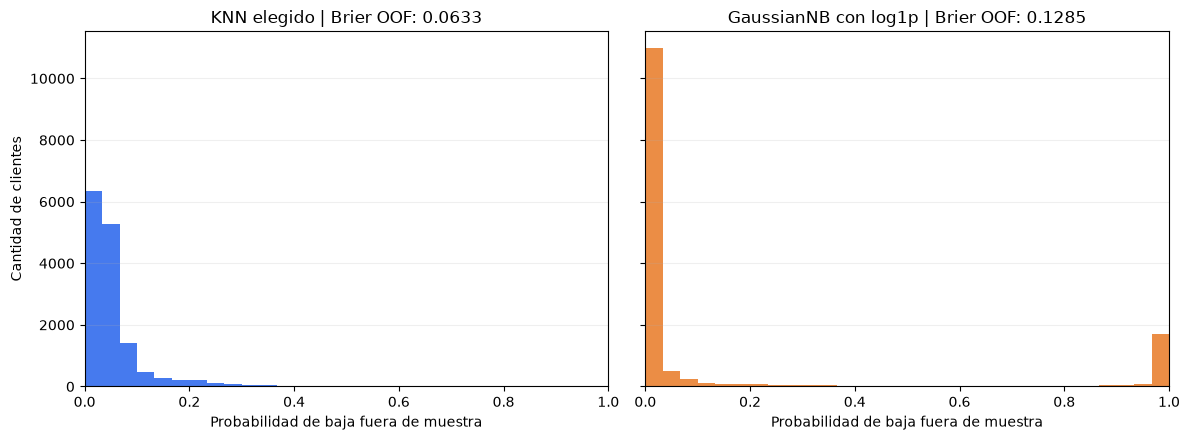

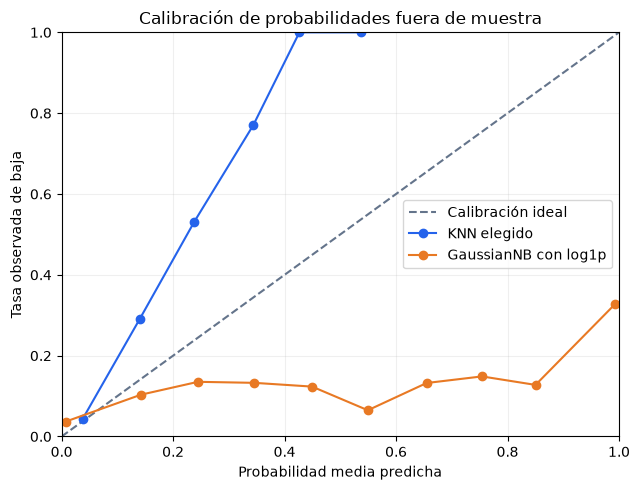

In [26]:

from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, brier_score_loss
from sklearn.model_selection import cross_val_predict

modelos_paso14 = {'KNN elegido': mejor_knn, nombre_mejor_nb: mejor_nb}
probabilidades_oof = pd.DataFrame(index=X_train.index)
for nombre, modelo in modelos_paso14.items():
    probabilidades_oof[nombre] = cross_val_predict(
        clone(modelo), X_train, y_train, cv=particiones_paso12,
        method='predict_proba', n_jobs=1,
    )[:, 1]  # clases ordenadas [0, 1]; cada fold aprende su preprocesamiento.

prob_referencia_oof = np.empty(len(y_train), dtype=float)
for indices_ajuste, indices_validacion in particiones_paso12:
    prob_referencia_oof[indices_validacion] = y_train.iloc[indices_ajuste].mean()
filas_paso14 = []
for nombre, prob in probabilidades_oof.items():
    riesgo_alto = prob >= 0.8
    filas_paso14.append({
        'Modelo': nombre,
        'Brier OOF (menor es mejor)': brier_score_loss(y_train, prob),
        'AP OOF': average_precision_score(y_train, prob),
        'Probabilidad media': prob.mean(),
        'Fracción p <= 0,05': (prob <= 0.05).mean(),
        'Fracción p >= 0,80': riesgo_alto.mean(),
        'Clientes p >= 0,80': riesgo_alto.sum(),
        'Probabilidad media p >= 0,80': prob[riesgo_alto].mean(),
        'Tasa real de baja p >= 0,80': y_train.loc[riesgo_alto].mean(),
    })
resumen_paso14 = pd.DataFrame(filas_paso14).set_index('Modelo')
display(resumen_paso14.round(4).T)
print(f'Brier de referencia constante OOF: {brier_score_loss(y_train, prob_referencia_oof):.4f}')
print(f'Tasa real de baja: {y_train.mean():.4f}')

fig_paso14, axes_paso14 = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True)
colores_paso14 = ['#2563eb', '#e87924']
for ax, (nombre, prob), color in zip(axes_paso14, probabilidades_oof.items(), colores_paso14):
    ax.hist(prob, bins=np.linspace(0, 1, 31), color=color, alpha=0.85)
    ax.set_title(f'{nombre} | Brier OOF: {brier_score_loss(y_train, prob):.4f}')
    ax.set_xlabel('Probabilidad de baja fuera de muestra')
    ax.set_xlim(0, 1)
    ax.grid(axis='y', alpha=0.2)
axes_paso14[0].set_ylabel('Cantidad de clientes')
fig_paso14.tight_layout()
fig_paso14.savefig('figuras/paso14_histogramas_oof.png', dpi=160, bbox_inches='tight')
plt.show()

fig_calibracion, ax_calibracion = plt.subplots(figsize=(6.5, 5))
ax_calibracion.plot([0, 1], [0, 1], '--', color='#64748b', label='Calibración ideal')
calibracion_paso14 = {}
for (nombre, prob), color in zip(probabilidades_oof.items(), colores_paso14):
    tasa_observada, media_predicha = calibration_curve(y_train, prob, n_bins=10, strategy='uniform')
    calibracion_paso14[nombre] = pd.DataFrame({
        'Probabilidad media': media_predicha, 'Tasa observada': tasa_observada,
    })
    ax_calibracion.plot(media_predicha, tasa_observada, 'o-', color=color, label=nombre)
ax_calibracion.set(xlabel='Probabilidad media predicha', ylabel='Tasa observada de baja',
                   title='Calibración de probabilidades fuera de muestra', xlim=(0, 1), ylim=(0, 1))
ax_calibracion.legend()
ax_calibracion.grid(alpha=0.2)
fig_calibracion.tight_layout()
fig_calibracion.savefig('figuras/paso14_calibracion_oof.png', dpi=160, bbox_inches='tight')
plt.show()

prob_oof_knn = probabilidades_oof['KNN elegido'].to_numpy()
prob_oof_nb = probabilidades_oof[nombre_mejor_nb].to_numpy()


### Conclusión del Paso 14

**GaussianNB exagera mucho más su confianza.** Asigna p ≥ 0,80 a 1.924 clientes (13,2% del entrenamiento), con una probabilidad media de 0,987, pero entre ellos solo se fue el **31,9%**. A la vez, el 77,7% recibe p ≤ 0,05: sus probabilidades se amontonan en los extremos. Es lo esperable al multiplicar verosimilitudes de variables que no son independientes (Paso 13): la misma señal de mala calidad se cuenta varias veces. Su Brier (0,1285) es peor incluso que predecir siempre la tasa de baja (0,0728).

**KNN hace lo contrario: subestima el riesgo.** Su probabilidad media es **0,053** cuando la tasa real es **0,079**, y no asigna p ≥ 0,80 a ningún cliente. Cada probabilidad es un promedio sobre 201 vecinos que mezcla a los clientes de riesgo con muchos que se quedan, y eso achata las probabilidades: ni los clientes más riesgosos reciben valores altos. Su Brier (0,0633) es el mejor de los tres, pero sus probabilidades sirven para **ordenar** a los clientes, no como probabilidad real de baja. Esto importa en la Parte E, al compararlas con el 29,5% de equilibrio.

El Brier combina calibración y discriminación. Estas probabilidades fuera de muestra usan las mismas particiones con que se eligió k, así que pueden ser algo optimistas; la confirmación es la prueba de la Parte E.

## Parte E · Economía de la campaña (`src/negocio.py`)

**Paso 15.** Implementen las funciones de `src/negocio.py` hasta que pasen `tests/test_negocio.py`. Informen G⁺, G⁻ y la probabilidad de equilibrio.

In [27]:
# Paso 15: resultado económico esperado por contacto.
from src.negocio import (
    SUPUESTOS, resultado_por_contacto, probabilidad_de_equilibrio,
    ganancia_campania, mejor_umbral, lift,
)

g_positivo, g_negativo = resultado_por_contacto()
p_equilibrio = probabilidad_de_equilibrio()
resumen_paso15 = pd.DataFrame({
    'Indicador': ['G+ (cliente que se iba)', 'G- (cliente que se quedaba)', 'Probabilidad de equilibrio'],
    'Valor': [g_positivo, g_negativo, p_equilibrio],
}).set_index('Indicador')
display(resumen_paso15)
print(f'G+: Gs. {g_positivo:,.0f} | G-: Gs. {g_negativo:,.0f}')
print(f'Probabilidad de equilibrio: {p_equilibrio:.2%}')
assert np.isclose(p_equilibrio * g_positivo + (1 - p_equilibrio) * g_negativo, 0)

,Valor
Indicador,
G+ (cliente que se iba),310000.000000
G- (cliente que se quedaba),-130000.000000
Probabilidad de equilibrio,0.295455


G+: Gs. 310,000 | G-: Gs. -130,000
Probabilidad de equilibrio: 29.55%


### Conclusión del Paso 15

Contactar a un cliente que se iba a ir deja un resultado esperado de **Gs. 310.000**: 0,40 × (1.000.000 − 200.000) − 10.000. Si el cliente se iba a quedar, el resultado es **−Gs. 130.000**: −0,60 × 200.000 − 10.000. No contactar deja resultado cero.

La probabilidad de equilibrio es **29,55%**, obtenida como 130.000 / (310.000 + 130.000). Para una probabilidad bien calibrada, contactar tiene valor esperado positivo por encima de ese nivel. Es una condición de rentabilidad por cliente; con cupo, además se priorizan los clientes de mayor riesgo. Las ganancias calculadas usan las probabilidades de aceptación de los supuestos y no son ingresos efectivamente observados.


**Paso 16.** Regla comercial sobre el conjunto de entrenamiento: clientes marcados, proporción que se fue y ganancia por cada 1.000 clientes.

In [28]:
# Paso 16: regla propuesta por el gerente comercial.
def regla_comercial(clientes):
    return (
        clientes['tipo_contrato'].eq('mensual')
        & clientes['reclamos_tecnicos_90d'].ge(2)
    )

contactar_regla_train = regla_comercial(X_train)
n_regla_train = int(contactar_regla_train.sum())
precision_regla_train = y_train.loc[contactar_regla_train].mean() if n_regla_train else 0.0
ganancia_regla_train = ganancia_campania(y_train, contactar_regla_train)
resumen_paso16 = pd.DataFrame([{
    'Clientes de entrenamiento': len(y_train),
    'Clientes marcados': n_regla_train,
    'Fracción marcada': n_regla_train / len(y_train),
    'Proporción que se fue entre marcados': precision_regla_train,
    'Ganancia esperada total (Gs.)': ganancia_regla_train,
    'Ganancia por 1.000 clientes (Gs.)': ganancia_regla_train * 1000 / len(y_train),
}])
display(resumen_paso16.round(4).T)

,0
Clientes de entrenamiento,1.454100e+04
Clientes marcados,9.410000e+02
Fracción marcada,6.470000e-02
Proporción que se fue entre marcados,2.274000e-01
Ganancia esperada total (Gs.),-2.817000e+07
Ganancia por 1.000 clientes (Gs.),-1.937281e+06


### Conclusión del Paso 16

La regla comercial marca a los clientes con **contrato mensual y al menos dos reclamos técnicos en 90 días**. En los 14.541 clientes residenciales de entrenamiento marca **941 (6,47%)**. Entre los marcados, **22,74%** se dio de baja.

Su ganancia esperada es **Gs. -28.170.000**, equivalente a **Gs. -1.937.281 por cada 1.000 clientes de la base**, no por cada 1.000 contactos. La regla se evalúa tal como fue propuesta y no se ajusta con estas bajas. Pierde plata porque la proporción de bajas entre los marcados (22,74%) queda por debajo del 29,55% de equilibrio del Paso 15: en promedio, cada llamada cuesta más de lo que recupera.

**Paso 17.** Umbral de cada modelo con `mejor_umbral` sobre probabilidades fuera de muestra, con un máximo del 7% de los clientes. Comparación con la probabilidad de equilibrio.

In [29]:
# Paso 17: seleccionar umbrales y modelo únicamente con probabilidades OOF.
MAX_FRACCION_CONTACTOS = 0.07  # 420 llamadas / 6.000 clientes de la campaña.
max_contactos_train = int(np.floor(MAX_FRACCION_CONTACTOS * len(y_train)))
probas_oof_modelos = {'KNN elegido': prob_oof_knn, nombre_mejor_nb: prob_oof_nb}
resultados_umbrales = {}
filas_paso17 = []
for nombre, prob in probas_oof_modelos.items():
    resultado = mejor_umbral(y_train, prob, max_contactos=max_contactos_train)
    resultados_umbrales[nombre] = resultado
    mascara = prob >= resultado['umbral']
    assert mascara.sum() == resultado['contactados'] <= max_contactos_train
    filas_paso17.append({
        'Modelo': nombre,
        'Umbral OOF': resultado['umbral'],
        'Ganancia OOF (Gs.)': resultado['ganancia'],
        'Ganancia por 1.000 clientes (Gs.)': resultado['ganancia'] * 1000 / len(y_train),
        'Contactados OOF': resultado['contactados'],
        'Fracción contactada': resultado['contactados'] / len(y_train),
        'Precisión de contactos OOF': y_train.loc[mascara].mean() if mascara.any() else 0.0,
        'Lift al 7%': lift(y_train, prob, MAX_FRACCION_CONTACTOS),
        'Diferencia con equilibrio': resultado['umbral'] - p_equilibrio,
    })
resumen_paso17 = pd.DataFrame(filas_paso17).set_index('Modelo')
display(resumen_paso17.round(6).T)
print(f'Cupo en entrenamiento: {max_contactos_train} de {len(y_train)} clientes')
print(f'Probabilidad de equilibrio teórica: {p_equilibrio:.6f}')

# Se congela la elección antes de consultar y_test.
nombre_modelo_elegido = resumen_paso17['Ganancia OOF (Gs.)'].idxmax()
modelo_elegido = modelos_paso14[nombre_modelo_elegido]
umbral_elegido = resultados_umbrales[nombre_modelo_elegido]['umbral']
print('Modelo elegido por ganancia OOF:', nombre_modelo_elegido)
print(f'Umbral congelado: {umbral_elegido:.10f}')

Modelo,KNN elegido,GaussianNB con log1p
Umbral OOF,1.542670e-01,9.999860e-01
Ganancia OOF (Gs.),8.614000e+07,4.493000e+07
Ganancia por 1.000 clientes (Gs.),5.923939e+06,3.089884e+06
Contactados OOF,8.300000e+02,5.310000e+02
Fracción contactada,5.708000e-02,3.651700e-02
Precisión de contactos OOF,5.313250e-01,4.877590e-01
Lift al 7%,6.111021e+00,4.819260e+00
Diferencia con equilibrio,-1.411870e-01,7.045310e-01


Cupo en entrenamiento: 1017 de 14541 clientes
Probabilidad de equilibrio teórica: 0.295455
Modelo elegido por ganancia OOF: KNN elegido
Umbral congelado: 0.1542673858


### Conclusión del Paso 17

Los umbrales se eligen con probabilidades fuera de muestra y un máximo de **1.017 contactos** en entrenamiento: floor(0,07 × 14.541). El 7% corresponde a las 420 llamadas sobre 6.000 clientes de la campaña.

| Modelo | Umbral OOF | Contactos | Bajas entre contactados | Ganancia esperada OOF (Gs.) |
|---|---:|---:|---:|---:|
| KNN elegido | 0,1543 | 830 | 53,1% | 86.140.000 |
| GaussianNB con log1p | 0,99999 | 531 | 48,8% | 44.930.000 |

Se congela **KNN elegido**, con umbral **0,1542673858**, por su mayor ganancia OOF, antes de mirar los resultados de prueba.

**El umbral no coincide con el 29,5% de equilibrio, y no tiene por qué.** El umbral de KNN (0,15) está muy por debajo del equilibrio y, sin embargo, entre los clientes contactados se fue el **53,1%**, bastante más que el 29,5% necesario para ganar. Confirma lo visto en el Paso 14: las probabilidades de KNN están comprimidas hacia abajo y un puntaje de 0,15 ya corresponde a los clientes de mayor riesgo. Con GaussianNB pasa lo contrario: su umbral (0,99999) queda muy por encima del equilibrio porque sobreestima su confianza. El 29,5% vale para probabilidades calibradas; con estos modelos el umbral se elige mirando el resultado económico de cada corte, no tomando las probabilidades al pie de la letra.

La búsqueda incluye a todos los clientes empatados en un mismo puntaje y descarta los umbrales que exceden el cupo. Ante igual ganancia se elige el que requiere menos contactos; si ninguna opción gana, se propone no contactar (`umbral = inf`). El resultado OOF sirve para elegir la política y puede ser algo optimista; la prueba se usa para evaluarla.

**Paso 18.** Evaluación única en prueba: tabla de estrategias y curva de ganancia acumulada.

Estrategia,No contactar,Regla comercial,KNN elegido,GaussianNB con log1p
Umbral OOF,NaN,NaN,0.154267,0.999986
Contactados,0,324,279,159
Fracción contactada,0.0,0.066845,0.057561,0.032804
Bajas entre contactados,0,72,145,95
Precisión de contactos,0.0,0.222222,0.519713,0.597484
Recall de bajas,0.0,0.18799,0.37859,0.248042
Ganancia esperada (Gs.),0.0,-10440000.0,27530000.0,21130000.0
Ganancia por 1.000 clientes (Gs.),0.0,-2153909.634826,5679801.939344,4359397.565504
Cumple cupo,True,True,True,True
AP en prueba,NaN,NaN,0.437743,0.406398


Cupo de prueba: 339 de 4847 clientes
La elección se mantiene según OOF: KNN elegido


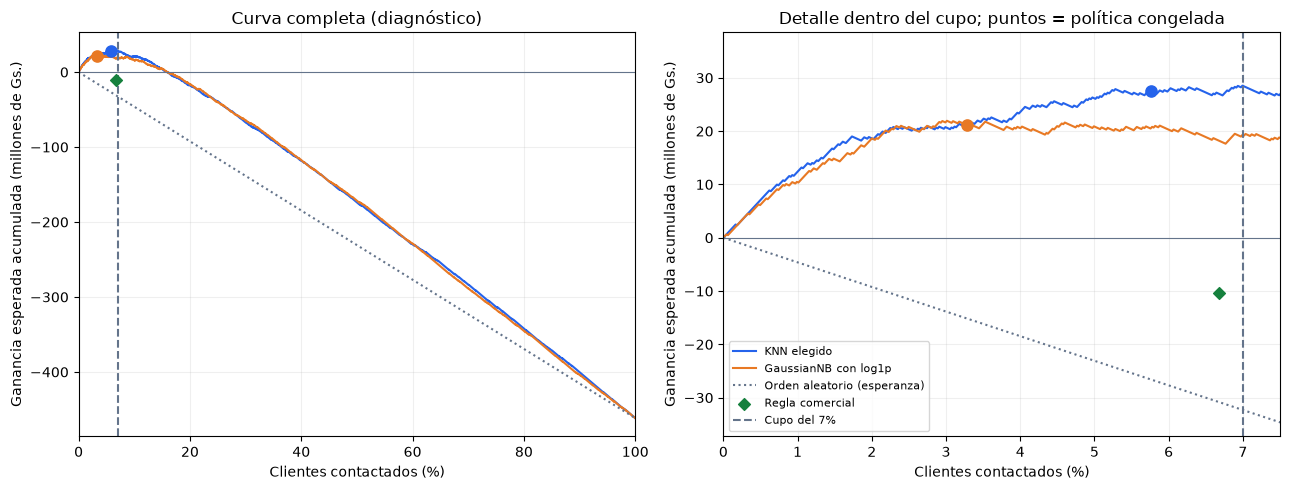

In [30]:
# Paso 18: evaluación de las políticas congeladas en el conjunto de prueba.
from pathlib import Path
from sklearn.metrics import average_precision_score, brier_score_loss

max_contactos_test = int(np.floor(MAX_FRACCION_CONTACTOS * len(y_test)))
ids_test = df_clean.loc[X_test.index, 'id_cliente'].to_numpy(dtype=str)

def aplicar_umbral_con_cupo(prob, umbral, max_contactos, ids):
    # El umbral se mantiene fijo. Si hay exceso de candidatos, se prioriza riesgo;
    # los empates se resuelven por id_cliente, sin consultar las bajas reales.
    prob = np.asarray(prob, dtype=float)
    candidatos = np.flatnonzero(prob >= umbral)
    orden = np.lexsort((np.asarray(ids)[candidatos], -prob[candidatos]))
    elegidos = candidatos[orden[:max_contactos]]
    mascara = np.zeros(len(prob), dtype=bool)
    mascara[elegidos] = True
    return mascara

probabilidades_test = {}
mascaras_test = {'No contactar': np.zeros(len(y_test), dtype=bool)}
mascara_regla_test = regla_comercial(X_test).to_numpy()
mascaras_test['Regla comercial'] = mascara_regla_test
if mascara_regla_test.sum() > max_contactos_test:
    mascaras_test['Regla comercial con cupo'] = aplicar_umbral_con_cupo(
        mascara_regla_test.astype(float), 1.0, max_contactos_test, ids_test,
    )
for nombre, modelo in modelos_paso14.items():
    prob = modelo.predict_proba(X_test)[:, 1]
    probabilidades_test[nombre] = prob
    mascaras_test[nombre] = aplicar_umbral_con_cupo(
        prob, resultados_umbrales[nombre]['umbral'], max_contactos_test, ids_test,
    )

filas_paso18 = []
for nombre, mascara in mascaras_test.items():
    n_contactados = int(mascara.sum())
    bajas_contactadas = int(y_test.to_numpy()[mascara].sum())
    ganancia = ganancia_campania(y_test, mascara)
    filas_paso18.append({
        'Estrategia': nombre,
        'Umbral OOF': resultados_umbrales[nombre]['umbral'] if nombre in resultados_umbrales else np.nan,
        'Contactados': n_contactados,
        'Fracción contactada': n_contactados / len(y_test),
        'Bajas entre contactados': bajas_contactadas,
        'Precisión de contactos': bajas_contactadas / n_contactados if n_contactados else 0.0,
        'Recall de bajas': bajas_contactadas / y_test.sum(),
        'Ganancia esperada (Gs.)': ganancia,
        'Ganancia por 1.000 clientes (Gs.)': ganancia * 1000 / len(y_test),
        'Cumple cupo': n_contactados <= max_contactos_test,
        'AP en prueba': average_precision_score(y_test, probabilidades_test[nombre]) if nombre in probabilidades_test else np.nan,
        'Brier en prueba': brier_score_loss(y_test, probabilidades_test[nombre]) if nombre in probabilidades_test else np.nan,
    })
resumen_paso18 = pd.DataFrame(filas_paso18).set_index('Estrategia')
display(resumen_paso18.round(6).T)
print(f'Cupo de prueba: {max_contactos_test} de {len(y_test)} clientes')
print('La elección se mantiene según OOF:', nombre_modelo_elegido)
contactar_test_elegido = mascaras_test[nombre_modelo_elegido]
prob_test_elegido = probabilidades_test[nombre_modelo_elegido]
assert contactar_test_elegido.sum() <= max_contactos_test
assert df_clean.loc[X_train.index, 'segmento'].eq('residencial').all()
assert df_clean.loc[X_test.index, 'segmento'].eq('residencial').all()

fig_paso18, axes_paso18 = plt.subplots(1, 2, figsize=(13, 5))
curvas_ganancia_test = {}
colores_paso18 = {'KNN elegido': '#2563eb', nombre_mejor_nb: '#e87924'}
for nombre, prob in probabilidades_test.items():
    orden = np.lexsort((ids_test, -prob))
    aportes = np.where(y_test.to_numpy()[orden] == 1, g_positivo, g_negativo)
    acumulada = np.r_[0.0, np.cumsum(aportes)]
    fraccion = np.arange(len(y_test) + 1) / len(y_test)
    curvas_ganancia_test[nombre] = acumulada
    for ax in axes_paso18:
        ax.plot(fraccion * 100, acumulada / 1e6, label=nombre, color=colores_paso18[nombre])
        fila = resumen_paso18.loc[nombre]
        ax.scatter(fila['Fracción contactada'] * 100, fila['Ganancia esperada (Gs.)'] / 1e6,
                   color=colores_paso18[nombre], marker='o', s=65, zorder=5)
ganancia_por_azar = y_test.mean() * g_positivo + (1 - y_test.mean()) * g_negativo
for ax in axes_paso18:
    ax.plot(fraccion * 100, np.arange(len(y_test) + 1) * ganancia_por_azar / 1e6,
            ':', color='#64748b', label='Orden aleatorio (esperanza)')
    ax.scatter(resumen_paso18.loc['Regla comercial', 'Fracción contactada'] * 100,
               resumen_paso18.loc['Regla comercial', 'Ganancia esperada (Gs.)'] / 1e6,
               marker='D', color='#15803d', label='Regla comercial', zorder=5)
    ax.axhline(0, color='#64748b', linewidth=0.8)
    ax.axvline(7, color='#64748b', linestyle='--', label='Cupo del 7%')
    ax.set_xlabel('Clientes contactados (%)')
    ax.set_ylabel('Ganancia esperada acumulada (millones de Gs.)')
    ax.grid(alpha=0.2)
axes_paso18[0].set(title='Curva completa (diagnóstico)', xlim=(0, 100))
axes_paso18[1].set(title='Detalle dentro del cupo; puntos = política congelada', xlim=(0, 7.5))
axes_paso18[1].set_ylim(
    min(0, ganancia_por_azar * max_contactos_test / 1e6,
        resumen_paso18.loc['Regla comercial', 'Ganancia esperada (Gs.)'] / 1e6,
        min(curva[:max_contactos_test+1].min() for curva in curvas_ganancia_test.values()) / 1e6) - 5,
    max(curva[:max_contactos_test+1].max() for curva in curvas_ganancia_test.values()) / 1e6 + 10,
)
axes_paso18[1].legend(fontsize=8, loc='lower left')
fig_paso18.tight_layout()
Path('figuras').mkdir(exist_ok=True)
fig_paso18.savefig('figuras/paso18_ganancia_acumulada.png', dpi=160, bbox_inches='tight')
plt.show()

### Conclusión del Paso 18

La política elegida previamente, **KNN elegido**, contacta a **279 de 4.847 clientes residenciales de prueba (5,76%)**, dentro del máximo de **339**. Entre los contactados se fue el **52,0%** y la ganancia esperada es **Gs. 27.530.000** (Gs. 5.679.802 por cada 1.000 clientes), en línea con lo estimado fuera de muestra (Gs. 5.923.939 por cada 1.000). La regla comercial contacta a 324 clientes, respeta el cupo y **pierde Gs. 10.440.000**: solo el 22,2% de sus contactos se fue, por debajo del 29,5% de equilibrio. GaussianNB logra mayor precisión (59,7%) pero, por su umbral extremo, contacta solo a 159 clientes, deja sin usar la mitad del cupo y gana menos (Gs. 21.130.000).

Los umbrales y el modelo se mantienen según la elección OOF: no se buscan umbrales nuevos ni se cambia de modelo por la ganancia de prueba. Si el umbral marcara más clientes que los permitidos, se conserva el umbral y se aplica el cupo priorizando riesgo, con desempate por id_cliente, sin usar y_test.

Las curvas muestran la ganancia acumulada al contactar por riesgo; los puntos identifican las políticas congeladas y la línea punteada, la esperanza de contactar al azar. Los máximos de esas curvas son diagnósticos, no umbrales para volver a ajustar la campaña. La ganancia es esperada bajo los supuestos de aceptación; medir el efecto real de la retención requiere un grupo de control.

modelo_elegido, umbral_elegido, prob_test_elegido y contactar_test_elegido quedan disponibles para las partes siguientes. En la Parte G el cupo es de **420 llamadas en valor absoluto**: de los 6.000 clientes de la campaña, 157 son empleados y se excluyen, así que las 420 llamadas se reparten entre 5.843 residenciales (≈7,2%).

## Parte F · Explicación para Fidelización

**Paso 19.** Importancia por permutación del modelo elegido sobre prueba (`average_precision`).

AP en prueba sin permutar: 0.4377


,Variable,Caída de AP (media),Desvío entre repeticiones,Caída relativa
0,consulto_baja_web_30d,0.1707,0.0159,0.3900
1,grupo_segmento,0.0572,0.0057,0.1307
2,zona,0.0240,0.0036,0.0547
3,velocidad_medida_pct,0.0239,0.0059,0.0545
4,sin_permanencia_3m,0.0220,0.0061,0.0502
5,plan_mbps,0.0209,0.0040,0.0478
6,reclamos_tecnicos_90d,0.0195,0.0072,0.0446
7,cargo_mensual_gs,0.0140,0.0025,0.0320
8,tipo_contrato,0.0093,0.0049,0.0213
9,facturas_atrasadas_6m,0.0089,0.0023,0.0203


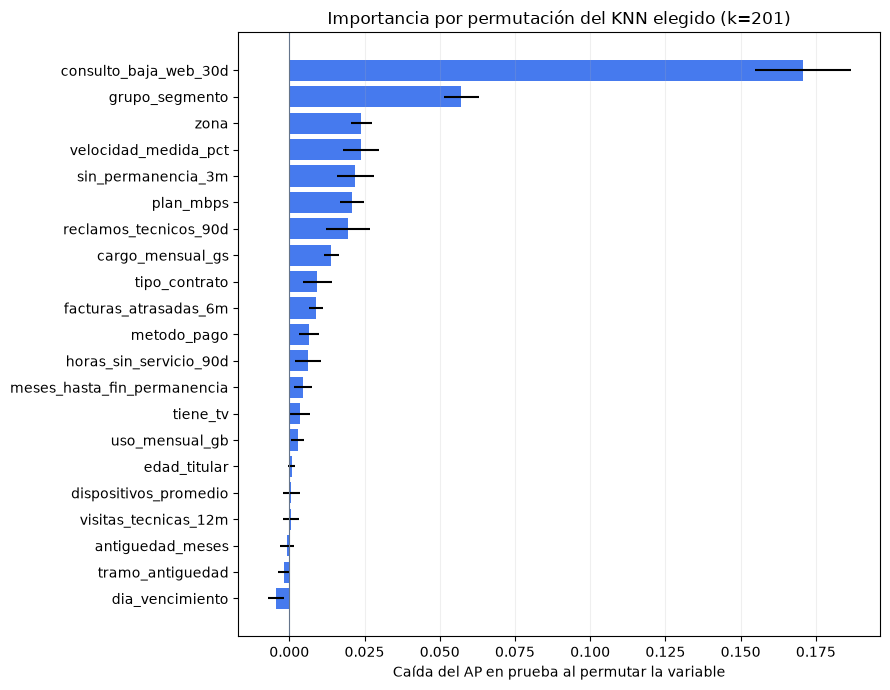

In [31]:
# Paso 19: importancia por permutación del modelo elegido sobre el conjunto de prueba.
# Se permutan las variables originales (antes del one-hot): cada barra es una variable de negocio.
from sklearn.inspection import permutation_importance

ap_prueba_elegido = average_precision_score(y_test, modelo_elegido.predict_proba(X_test)[:, 1])
importancia_perm = permutation_importance(
    modelo_elegido, X_test, y_test, scoring='average_precision',
    n_repeats=10, random_state=SEMILLA, n_jobs=-1,
)
tabla_importancia = pd.DataFrame({
    'Variable': X_test.columns,
    'Caída de AP (media)': importancia_perm.importances_mean,
    'Desvío entre repeticiones': importancia_perm.importances_std,
}).sort_values('Caída de AP (media)', ascending=False).reset_index(drop=True)
tabla_importancia['Caída relativa'] = tabla_importancia['Caída de AP (media)'] / ap_prueba_elegido

print(f'AP en prueba sin permutar: {ap_prueba_elegido:.4f}')
display(tabla_importancia.round(4))

fig_paso19, ax_paso19 = plt.subplots(figsize=(9, 7))
orden_paso19 = tabla_importancia.iloc[::-1]
ax_paso19.barh(
    orden_paso19['Variable'], orden_paso19['Caída de AP (media)'],
    xerr=orden_paso19['Desvío entre repeticiones'], color='#2563eb', alpha=0.85,
)
ax_paso19.axvline(0, color='#64748b', linewidth=0.8)
ax_paso19.set_xlabel('Caída del AP en prueba al permutar la variable')
ax_paso19.set_title(f'Importancia por permutación del KNN elegido (k={k_elegido})')
ax_paso19.grid(axis='x', alpha=0.2)
fig_paso19.tight_layout()
fig_paso19.savefig('figuras/paso19_importancia_permutacion.png', dpi=160, bbox_inches='tight')
plt.show()

### Conclusión del Paso 19

Sin permutar, el KNN elegido tiene un AP de **0,4377** en prueba. La importancia de cada variable es cuánto cae ese AP cuando se mezclan sus valores entre clientes.

- **`consulto_baja_web_30d` es, por lejos, la señal más fuerte:** permutarla hace caer el AP en **0,171**, el 39% del total. Es la intención explícita de irse. Se conoce antes de la fecha de corte, así que es una variable legítima, pero indica que estos clientes ya están decidiendo: la llamada tiene que llegar rápido.
- **La zona este con cargo alto viene después:** `grupo_segmento` (0,057) más `zona` (0,024) confirman el foco geográfico del Paso 3.
- **Calidad del servicio:** `velocidad_medida_pct` (0,024) y `reclamos_tecnicos_90d` (0,020) aportan, junto con `plan_mbps` (0,021) y `cargo_mensual_gs` (0,014).
- **La permanencia parece poco importante variable por variable** (`sin_permanencia_3m` 0,022, `tipo_contrato` 0,009, `meses_hasta_fin_permanencia` 0,005), pero en el Paso 11 retirar las tres juntas costaba 0,064 de AP. Son redundantes: al permutar una, las otras siguen llevando la información. Lo mismo pasa con `antiguedad_meses` y `tramo_antiguedad`, y entre `zona` y `grupo_segmento`. La permutación individual subestima a los grupos de variables correlacionadas.
- **`edad_titular`, `dispositivos_promedio` y `dia_vencimiento`** quedan en cero o por debajo (la caída negativa es ruido), coherente con el Paso 11.

La importancia describe qué información usa el modelo para ordenar el riesgo, no qué causa las bajas.

**Paso 20.** Función `explicar_cliente(id_cliente)` y su aplicación a los 3 clientes de mayor riesgo de la campaña, con la oferta propuesta para cada uno.

In [32]:
# Paso 20: explicación de un cliente a partir de los clientes del pasado más parecidos.

# Clientes de la campaña con la misma preparación que el histórico.
campania = agregar_variables(pd.read_csv('datos/clientes_campania.csv'))
campania = campania.loc[campania['segmento'].eq('residencial')]
campania = agregar_variables_derivadas(campania).set_index('id_cliente', drop=False)
assert campania.index.is_unique

# Puntaje preliminar con el modelo elegido (entrenado con el 75% del histórico).
# En el Paso 21 se reentrena con todo el histórico.
prob_campania_preliminar = pd.Series(
    modelo_elegido.predict_proba(campania[X_train.columns])[:, 1], index=campania.index,
)

# Los vecinos se buscan con nuestro KNNClasificador, en el mismo espacio del modelo elegido:
# variables preprocesadas por su ColumnTransformer, con su k, sus pesos y su distancia.
prep_elegido = modelo_elegido.named_steps['preprocessor']
knn_sklearn_elegido = modelo_elegido.named_steps['knn']
knn_explicacion = KNNClasificador(
    k=knn_sklearn_elegido.n_neighbors,
    pesos={'uniform': 'uniforme', 'distance': 'distancia'}[knn_sklearn_elegido.weights],
    metrica={1: 'manhattan', 2: 'euclidea'}[knn_sklearn_elegido.p],
).fit(prep_elegido.transform(X_train), y_train)
# Clientes de referencia: el entrenamiento, en el mismo orden con que se ajustó el KNN.
# Conservan motivo_baja: no entra al modelo, pero explica por qué se fueron los vecinos.
referencia_vecinos = df_clean.loc[X_train.index]

COLUMNAS_PERFIL = [
    'zona', 'tipo_contrato', 'meses_hasta_fin_permanencia', 'antiguedad_meses',
    'cargo_mensual_gs', 'plan_mbps', 'reclamos_tecnicos_90d', 'velocidad_medida_pct',
    'horas_sin_servicio_90d', 'facturas_atrasadas_6m', 'consulto_baja_web_30d',
]
OFERTAS = {
    'precio': 'descuento en la tarifa o pasar a un plan más barato',
    'competencia': 'igualar la oferta de la competencia con el descuento atado a un contrato de 12 meses',
    'calidad_servicio': 'resolver primero la calidad (visita técnica prioritaria) y después ofrecer el descuento',
    'mudanza': 'traslado del servicio sin costo al nuevo domicilio (el descuento no evita una mudanza)',
    'otros': 'llamada de fidelización con el descuento estándar',
}
# Umbrales de las señales propias del cliente. En el histórico, por debajo del 70% de velocidad o con
# 12 horas o más sin servicio la tasa de baja se duplica o más y "calidad_servicio" pasa a ser el
# motivo más frecuente; con 2 o más facturas atrasadas, "precio" sube de 24% a 44% de los motivos.
VELOCIDAD_BAJA_PCT = 70
HORAS_SIN_SERVICIO_ALTAS = 12
RECLAMOS_ALTOS = 2
FACTURAS_ATRASADAS_ALTAS = 2


def proponer_oferta(cliente, motivos):
    """Oferta según los motivos de baja de los vecinos, adaptada a las señales del propio cliente."""
    if motivos.empty:
        return 'Ningún vecino se fue: no hay un motivo que oriente la oferta.'
    motivo = motivos.index[0]
    texto_motivos = f'{motivo} ({motivos.iloc[0]:.0%})'
    if len(motivos) > 1 and motivos.iloc[1] >= motivos.iloc[0] - 0.10:
        texto_motivos += f' y {motivos.index[1]} ({motivos.iloc[1]:.0%})'
    partes = [f'Sus vecinos se fueron sobre todo por {texto_motivos}. Base: {OFERTAS[motivo]}.']

    problemas_calidad = []
    if cliente['velocidad_medida_pct'] < VELOCIDAD_BAJA_PCT:
        problemas_calidad.append(f"recibe el {cliente['velocidad_medida_pct']:.0f}% de la velocidad contratada")
    if cliente['horas_sin_servicio_90d'] >= HORAS_SIN_SERVICIO_ALTAS:
        problemas_calidad.append(f"estuvo {cliente['horas_sin_servicio_90d']:.0f} horas sin servicio en 90 días")
    if cliente['reclamos_tecnicos_90d'] >= RECLAMOS_ALTOS:
        problemas_calidad.append(f"hizo {cliente['reclamos_tecnicos_90d']} reclamos técnicos en 90 días")
    if problemas_calidad and motivo != 'calidad_servicio':
        partes.append('Además ' + ' y '.join(problemas_calidad)
                      + ': agendar una visita técnica; un descuento sobre un servicio que falla no retiene.')
    if cliente['facturas_atrasadas_6m'] >= FACTURAS_ATRASADAS_ALTAS and motivo != 'precio':
        partes.append(f"Tiene {cliente['facturas_atrasadas_6m']} facturas atrasadas en 6 meses: es sensible al precio; "
                      'conviene un plan más barato y estable antes que un descuento temporal.')
    if cliente['tipo_contrato'] == 'mensual' and motivo not in ('competencia', 'mudanza'):
        partes.append('Contrato mensual: condicionar el descuento a un contrato con permanencia.')
    return ' '.join(partes)


def explicar_cliente(id_cliente, clientes=None, n_mostrar=5):
    """Explica el riesgo de un cliente con sus vecinos del histórico.

    Devuelve un dict con la probabilidad de baja, el perfil del cliente, los `n_mostrar` vecinos más
    parecidos (con su resultado y motivo de baja), el reparto de motivos entre todos los vecinos que se
    fueron (ponderado como en el modelo) y la oferta propuesta.
    """
    clientes = campania if clientes is None else clientes
    cliente = clientes.loc[[id_cliente]]
    consulta = prep_elegido.transform(cliente[X_train.columns])
    distancias, indices = knn_explicacion.kneighbors(consulta)
    distancias, indices = distancias[0], indices[0]
    if (distancias == 0).any():
        pesos = (distancias == 0).astype(float)
    else:
        pesos = 1 / distancias if knn_explicacion.pesos == 'distancia' else np.ones_like(distancias)

    vecinos = referencia_vecinos.iloc[indices].assign(distancia=distancias, peso=pesos / pesos.sum())
    se_fueron = vecinos['baja_90d'].eq(1)
    motivos = (
        vecinos.loc[se_fueron].groupby('motivo_baja')['peso'].sum()
        .div(vecinos.loc[se_fueron, 'peso'].sum()).sort_values(ascending=False)
    )
    return {
        'id_cliente': id_cliente,
        'prob_baja': float(knn_explicacion.predict_proba(consulta)[0, 1]),
        'perfil': cliente[COLUMNAS_PERFIL].iloc[0],
        'vecinos': vecinos.head(n_mostrar)[
            ['id_cliente', 'distancia', 'baja_90d', 'motivo_baja'] + COLUMNAS_PERFIL
        ].reset_index(drop=True),
        'vecinos_que_se_fueron': int(se_fueron.sum()),
        'motivos': motivos,
        'oferta': proponer_oferta(cliente.iloc[0], motivos),
    }


top3_campania = (
    prob_campania_preliminar.rename('prob_baja').reset_index()
    .sort_values(['prob_baja', 'id_cliente'], ascending=[False, True]).head(3)
)
explicaciones_top3 = {}
for posicion, id_cliente in enumerate(top3_campania['id_cliente'], start=1):
    explicacion = explicar_cliente(id_cliente)
    explicaciones_top3[id_cliente] = explicacion
    # Nuestro KNN reproduce la probabilidad del modelo elegido.
    assert np.isclose(explicacion['prob_baja'], prob_campania_preliminar[id_cliente])

    print(f"\n{'=' * 90}\n{posicion}. Cliente {id_cliente} | probabilidad de baja: {explicacion['prob_baja']:.3f}")
    display(explicacion['perfil'].to_frame('Cliente').T.round(1))
    print(f"Los {len(explicacion['vecinos'])} clientes del pasado más parecidos:")
    display(explicacion['vecinos'].round(2))
    print(f"Entre sus {knn_explicacion.k} vecinos se fueron {explicacion['vecinos_que_se_fueron']}. "
          'Motivos de baja (ponderados por cercanía):')
    display(explicacion['motivos'].map('{:.0%}'.format).to_frame('Proporción').T)
    print('Oferta propuesta:', explicacion['oferta'])


1. Cliente NI-305479 | probabilidad de baja: 0.520


,zona,tipo_contrato,meses_hasta_fin_permanencia,antiguedad_meses,cargo_mensual_gs,plan_mbps,reclamos_tecnicos_90d,velocidad_medida_pct,horas_sin_servicio_90d,facturas_atrasadas_6m,consulto_baja_web_30d
Cliente,este,mensual,0.0,15.374507,428000,1000,0,52.7,22.3,0,1


Los 5 clientes del pasado más parecidos:


,id_cliente,distancia,baja_90d,motivo_baja,zona,tipo_contrato,meses_hasta_fin_permanencia,antiguedad_meses,cargo_mensual_gs,plan_mbps,reclamos_tecnicos_90d,velocidad_medida_pct,horas_sin_servicio_90d,facturas_atrasadas_6m,consulto_baja_web_30d
0,NI-106252,5.88,1,precio,este,mensual,0.00,22.93,403000,1000,1,55.0,4.3,0,1
1,NI-108791,7.99,1,competencia,este,12_meses,1.91,22.11,448000,1000,0,74.3,15.5,0,1
2,NI-102205,11.77,1,competencia,este,mensual,0.00,74.57,448000,1000,1,72.1,0.0,0,1
3,NI-107753,11.87,1,competencia,este,mensual,0.00,26.41,403000,1000,0,85.4,0.6,0,1
4,NI-105247,12.22,1,precio,este,mensual,0.00,35.78,379000,1000,0,63.4,0.0,0,1


Entre sus 201 vecinos se fueron 100. Motivos de baja (ponderados por cercanía):


...

Los 5 clientes del pasado más parecidos:


,id_cliente,distancia,baja_90d,motivo_baja,zona,tipo_contrato,meses_hasta_fin_permanencia,antiguedad_meses,cargo_mensual_gs,plan_mbps,reclamos_tecnicos_90d,velocidad_medida_pct,horas_sin_servicio_90d,facturas_atrasadas_6m,consulto_baja_web_30d
0,NI-105247,9.19,1,precio,este,mensual,0.0,35.78,379000,1000,0,63.4,0.0,0,1
1,NI-107753,10.18,1,competencia,este,mensual,0.0,26.41,403000,1000,0,85.4,0.6,0,1
2,NI-115845,10.90,0,NaN,centro,mensual,0.0,18.00,341000,1000,0,82.6,0.5,0,0
3,NI-118476,10.98,0,NaN,este,mensual,0.0,32.59,341000,1000,1,81.0,0.0,0,0
4,NI-110815,11.17,1,competencia,este,mensual,0.0,29.47,379000,1000,0,82.4,0.7,0,1


Entre sus 201 vecinos se fueron 90. Motivos de baja (ponderados por cercanía):


motivo_baja,competencia,precio,calidad_servicio,mudanza,otros
Proporción,46%,32%,10%,6%,6%


Oferta propuesta: Sus vecinos se fueron sobre todo por competencia (46%). Base: igualar la oferta de la competencia con el descuento atado a un contrato de 12 meses.


### Conclusión del Paso 20

`explicar_cliente` busca con nuestro `KNNClasificador` los 201 vecinos del cliente en el mismo espacio del modelo elegido: variables preprocesadas, distancia Manhattan y pesos por distancia. La probabilidad que calcula coincide con la del modelo (se verifica con `assert`), así que la explicación corresponde exactamente a la predicción. Le muestra al vendedor los **5 clientes del pasado más parecidos**, con su resultado y su motivo de baja. Como 5 vecinos son pocos para estimar motivos, también resume los motivos de **todos los vecinos que se fueron**, ponderados por cercanía. `motivo_baja` nunca entra al modelo: solo describe a clientes que ya se fueron.

Los tres clientes de mayor riesgo comparten el perfil que señalaban los Pasos 3 y 19: **zona este, contrato mensual, plan de 1.000 Mbps, cargo de Gs. 379.000 a 448.000 y consulta de baja en la web**. Entre sus 201 vecinos se fue casi la mitad (100, 96 y 90), sobre todo por **competencia y precio**. Lo que los distingue son sus propias señales, y eso cambia la oferta:

| Cliente | Prob. de baja | Motivos de sus vecinos | Señales propias | Oferta |
|---|---:|---|---|---|
| NI-305479 | 0,520 | competencia 36%, precio 33% | recibe el 53% de la velocidad contratada; 22 h sin servicio en 90 días | Visita técnica prioritaria **y** descuento que iguale a la competencia, atado a 12 meses. Sin resolver el servicio, el descuento no alcanza. |
| NI-301055 | 0,495 | competencia 37%, precio 26% | 66% de la velocidad; 2 facturas atrasadas en 6 meses | Visita técnica y un **plan más barato y estable** (por ejemplo, bajar de 1.000 Mbps) con permanencia, antes que un descuento temporal que no resuelve su problema de pago. |
| NI-305482 | 0,461 | competencia 46%, precio 32% | sin problemas de calidad ni de pago | Oferta competitiva pura: **igualar a la competencia** con el descuento atado a un contrato de 12 meses. |

Estos puntajes son preliminares: salen del modelo entrenado con el 75% del histórico. En el Paso 21 el modelo se reentrena con todo el histórico y la lista puede cambiar; Para explicar con el modelo final alcanza con redefinir `prep_elegido`, `knn_explicacion` y `referencia_vecinos` con él y con todo el histórico. Las probabilidades de 0,46 a 0,52 parecen moderadas, pero son las más altas de la campaña: KNN comprime las probabilidades hacia abajo (Paso 14).

## Parte G · Lista de la campaña de octubre

**Paso 21.** Reentrenen el modelo con todos los clientes residenciales del histórico y calculen la probabilidad de baja de `datos/clientes_campania.csv`.

In [1]:
# Paso 21: ajustar una copia del pipeline elegido con todo el histórico residencial.
from sklearn.base import clone

X_historico = df_clean.loc[:, X_train.columns]
y_historico = df_clean['baja_90d']
assert df_clean['segmento'].eq('residencial').all()
assert df_clean['id_cliente'].is_unique

# Se reaprenden imputación, escalado y categorías; se conservan los hiperparámetros.
# modelo_elegido y sus resultados de prueba siguen siendo los del Paso 18.
modelo_final = clone(modelo_elegido).fit(X_historico, y_historico)
campania_completa = agregar_variables_derivadas(
    agregar_variables(pd.read_csv('datos/clientes_campania.csv'))
)
assert len(campania_completa) == 6000
assert campania_completa['id_cliente'].notna().all()
assert campania_completa['id_cliente'].is_unique
assert campania_completa['segmento'].isin(['residencial', 'empleado']).all()

# Se puntúan las 6.000 filas. Los empleados se excluyen de la selección del Paso 22;
# su puntaje no se usa para decidir contactos, pues no son la población del modelo.
prob_campania_final = modelo_final.predict_proba(
    campania_completa.loc[:, X_train.columns]
)[:, 1]
assert np.isfinite(prob_campania_final).all()
assert ((prob_campania_final >= 0) & (prob_campania_final <= 1)).all()

print(f'Modelo final: {nombre_modelo_elegido}')
print(f'Clientes residenciales usados para reentrenar: {len(X_historico):,}')
print(f'Clientes puntuados: {len(campania_completa):,}')
print(f'Umbral OOF conservado: {umbral_elegido:.10f}')


Modelo final: KNN elegido
Clientes residenciales usados para reentrenar: 19,388
Clientes puntuados: 6,000
Umbral OOF conservado: 0.1542673858


### Conclusión del Paso 21

Se reentrena el pipeline KNN con los **19.388 clientes residenciales** del histórico: k=201, pesos por distancia y distancia Manhattan. Se vuelven a aprender la imputación, la estandarización y las categorías usando todo ese histórico, conservando las variables y los hiperparámetros elegidos. `modelo_final` es una copia independiente; `modelo_elegido` conserva el ajuste con entrenamiento y la evaluación de prueba del Paso 18.

Se calculan los puntajes de las **6.000 filas** de septiembre y se conserva el umbral OOF **0,1542673858**. Los 157 empleados también figuran en el archivo para cumplir la consigna, pero sus puntajes quedan fuera de la decisión comercial: el modelo se entrenó para clientes residenciales.

**Paso 22.** Generen `campania_octubre.csv` (6.000 filas; columnas `id_cliente`, `prob_baja`, `contactar`) y verifiquen: como máximo 420 contactos, ningún empleado, ningún cliente repetido.

In [2]:
# Paso 22: umbral congelado, elegibilidad residencial y cupo absoluto de 420.
from pathlib import Path

MAX_CONTACTOS_CAMPANIA = 420
es_residencial_campania = campania_completa['segmento'].eq('residencial').to_numpy()
contactar_campania = np.zeros(len(campania_completa), dtype=bool)
# Aplicar el cupo solo sobre residenciales: un empleado nunca ocupa una llamada.
contactar_campania[es_residencial_campania] = aplicar_umbral_con_cupo(
    prob_campania_final[es_residencial_campania], umbral_elegido,
    MAX_CONTACTOS_CAMPANIA,
    campania_completa.loc[es_residencial_campania, 'id_cliente'].to_numpy(dtype=str),
)
lista_campania = pd.DataFrame({
    'id_cliente': campania_completa['id_cliente'].to_numpy(),
    'prob_baja': prob_campania_final,
    'contactar': contactar_campania.astype(int),
})
n_candidatos_campania = int((
    es_residencial_campania & (prob_campania_final >= umbral_elegido)
).sum())
n_contactos_campania = int(lista_campania['contactar'].sum())

assert lista_campania.shape == (6000, 3)
assert lista_campania['id_cliente'].is_unique
assert n_contactos_campania <= MAX_CONTACTOS_CAMPANIA
assert not contactar_campania[~es_residencial_campania].any()
assert (prob_campania_final[contactar_campania] >= umbral_elegido).all()
assert n_contactos_campania == min(n_candidatos_campania, MAX_CONTACTOS_CAMPANIA)

# Se conserva el orden de la base; contactar se exporta como 0/1, sin índice extra.
ruta_campania = Path('campania_octubre.csv')
lista_campania.to_csv(ruta_campania, index=False, encoding='utf-8')
# Verificar también el archivo efectivamente escrito.
lista_exportada = pd.read_csv(ruta_campania)
pd.testing.assert_frame_equal(lista_exportada, lista_campania)

resumen_paso22 = pd.Series({
    'Filas exportadas': len(lista_exportada),
    'Clientes residenciales': int(es_residencial_campania.sum()),
    'Empleados sin contactar': int((~es_residencial_campania).sum()),
    'Residenciales que superan el umbral': n_candidatos_campania,
    'Contactos seleccionados': n_contactos_campania,
    'Cupo disponible sin usar': MAX_CONTACTOS_CAMPANIA - n_contactos_campania,
}, name='Cantidad')
display(resumen_paso22.to_frame())
print(f'Archivo generado y verificado: {ruta_campania}')
display(lista_campania.loc[contactar_campania].sort_values(
    ['prob_baja', 'id_cliente'], ascending=[False, True],
).head(10))


Archivo generado y verificado: campania_octubre.csv


,Cantidad
Filas exportadas,6000
Clientes residenciales,5843
Empleados sin contactar,157
Residenciales que superan el umbral,379
Contactos seleccionados,379
Cupo disponible sin usar,41


,id_cliente,prob_baja,contactar
3397,NI-305479,0.579849,1
1773,NI-301055,0.545894,1
4059,NI-301287,0.512263,1
5591,NI-305687,0.511963,1
5084,NI-301957,0.511042,1
1289,NI-305108,0.497448,1
5467,NI-304391,0.491135,1
5571,NI-304426,0.464387,1
2091,NI-305250,0.459521,1
1997,NI-305482,0.458986,1


### Conclusión del Paso 22

`campania_octubre.csv` contiene **6.000 clientes únicos** y exactamente las columnas `id_cliente`, `prob_baja` y `contactar` (0/1). Entre los **5.843 residenciales**, **379** alcanzan el umbral y quedan marcados para contactar; los **157 empleados** tienen `contactar = 0`. Las comprobaciones incluyen volver a leer el CSV guardado.

Quedan **41 llamadas disponibles**: 420 es un máximo, no una obligación de completar el cupo. No se baja el umbral para agregar clientes. Si hubiera más de 420 candidatos residenciales, se priorizaría la mayor probabilidad, con desempate por `id_cliente`, tal como se evaluó en prueba.

**Paso 23.** Ganancia esperada de la campaña con la precisión observada en prueba.

In [3]:
# Paso 23: extrapolar la precisión de la política evaluada en prueba (Paso 18).
# No se vuelve a evaluar el modelo final sobre el histórico que acaba de aprender.
n_contactos_prueba = int(np.asarray(contactar_test_elegido).sum())
bajas_contactadas_prueba = int(y_test.to_numpy()[contactar_test_elegido].sum())
if n_contactos_prueba == 0:
    raise ValueError('Sin contactos en prueba no se puede estimar su precisión.')
precision_prueba_elegido = bajas_contactadas_prueba / n_contactos_prueba
g_positivo_campania, g_negativo_campania = resultado_por_contacto()
ganancia_por_contacto_campania = (
    precision_prueba_elegido * g_positivo_campania
    + (1 - precision_prueba_elegido) * g_negativo_campania
)
ganancia_esperada_campania = n_contactos_campania * ganancia_por_contacto_campania
bajas_esperadas_contactadas = n_contactos_campania * precision_prueba_elegido
retenidos_esperados_campania = bajas_esperadas_contactadas * SUPUESTOS['acepta_si_se_iba']

resumen_paso23 = pd.Series({
    'Contactos de octubre': n_contactos_campania,
    'Precisión observada en prueba': precision_prueba_elegido,
    'Bajas esperadas entre contactos sin intervención': bajas_esperadas_contactadas,
    'Clientes retenidos esperados': retenidos_esperados_campania,
    'Ganancia esperada por contacto (Gs.)': ganancia_por_contacto_campania,
    'Ganancia esperada total (Gs.)': ganancia_esperada_campania,
}, name='Estimación')
display(resumen_paso23.to_frame().round(4))
print(f'Precisión de prueba: {bajas_contactadas_prueba}/{n_contactos_prueba} '
      f'= {precision_prueba_elegido:.2%}')
print(f'Ganancia esperada: {n_contactos_campania} × '
      f'({precision_prueba_elegido:.6f} × {g_positivo_campania:,.0f} '
      f'+ {1 - precision_prueba_elegido:.6f} × {g_negativo_campania:,.0f}) '
      f'= Gs. {ganancia_esperada_campania:,.0f}')


Precisión de prueba: 145/279 = 51.97%
Ganancia esperada: 379 × (0.519713 × 310,000 + 0.480287 × -130,000) = Gs. 37,397,384


,Estimación
Contactos de octubre,3.790000e+02
Precisión observada en prueba,5.197000e-01
Bajas esperadas entre contactos sin intervención,1.969713e+02
Clientes retenidos esperados,7.878850e+01
Ganancia esperada por contacto (Gs.),9.867384e+04
Ganancia esperada total (Gs.),3.739738e+07


### Conclusión del Paso 23

En prueba, **145 de los 279 contactos** se dieron de baja: precisión **51,97%**. Si esa precisión se mantiene en octubre, la ganancia esperada de los 379 contactos es:

$$379 \times \left(\frac{145}{279} \times 310.000 + \frac{134}{279} \times (-130.000)\right) = \text{Gs. }37.397.384$$

Son aproximadamente **Gs. 98.674 por contacto**. Entre los contactados se esperarían **197 bajas sin intervención** y, con la aceptación del 40% prevista para quienes se iban a ir, unos **79 clientes retenidos**. El cálculo ya incluye los costos esperados del contacto y del descuento, también para quienes se habrían quedado.

Esta proyección usa la precisión observada en prueba y los supuestos de Finanzas, no el promedio de los puntajes KNN, que no están bien calibrados. Supone que la selección del modelo reentrenado y la población de septiembre mantienen esa precisión; un cambio de población o de comportamiento puede modificarla. Es una ganancia esperada bajo esos supuestos, no un efecto de retención ya medido: para medirlo hace falta un grupo de control.

## Parte H · Informe ejecutivo

**Paso 24.** El informe para Martín Aquino se entrega aparte, en `informe_ejecutivo.pdf`.

## Preguntas de reflexión profesional

Respondan cada pregunta en un párrafo, apoyándose en sus resultados.

**1. `motivo_baja` no puede ser variable del modelo, pero sí se usó para explicar a los vecinos. ¿Por qué un uso es incorrecto y el otro no?**

_Respuesta:_ 

**2. ¿Por qué KNN necesita estandarizar las variables y Naive Bayes gaussiano no?**

_Respuesta:_ 

**3. ¿Qué dice la diferencia entre el umbral elegido y la probabilidad de equilibrio sobre las probabilidades de KNN? ¿Qué le responderían a Finanzas?**

_Respuesta:_ 

**4. ¿Cómo medirían el efecto real de la campaña de octubre?**

_Respuesta:_ 

**5. ¿Es aceptable ofrecer descuentos solo a algunos clientes según su zona o su perfil? ¿Qué riesgos ven?**

_Respuesta:_ 

**6. ¿Qué implica que KNN guarde los datos de entrenamiento para actualizar el modelo y para la privacidad?**

_Respuesta:_ 

**7. ¿Qué pudo cambiar entre la foto de mayo y la de septiembre y cómo lo detectarían antes de lanzar la campaña?**

_Respuesta:_ 